# Evaluacion Parcial Nro 2 - Deep Learning - DUOC UC
## 2do semestre 2026
----

## Nombre de los integrantes del Grupo
----

- Antonio Cornejo
- Cristopher Silva
- Pablo Toro

## **Importante: La entrega se debe realizar mediante GitHub**

## Convolutional Neural Networks

En esta actividad, vamos a trabajar con Convolutional Neural Networks para resolver un problema de clasificación de imágenes. En particular, vamos a clasificar imágenes de personajes de la conocida serie de los Simpsons.

Como las CNN profundas son un tipo de modelo bastante avanzado y computacionalmente costoso, se recomienda hacer la práctica en Google Colaboratory con soporte para GPUs. En [este enlace](https://medium.com/deep-learning-turkey/google-colab-free-gpu-tutorial-e113627b9f5d) se explica cómo activar un entorno con GPUs. *Nota: para leer las imágenes y estandarizarlas al mismo tamaño se usa la librería opencv. Esta ĺibrería está ya instalada en el entorno de Colab. (Si trabajan de manera local deberán instalarla)*

<center><img src="https://i.imgur.com/i8zIGqX.jpg" style="text-align: center" height="300px"></center>

El dataset a utilizar consiste en imágenes de personajes de los Simpsons extraídas directamente de capítulos de la serie. Este dataset ha sido recopilado por [Alexandre Attia](http://www.alexattia.fr/) y es más complejo que el dataset de Fashion MNIST que hemos utilizado hasta ahora. Aparte de tener más clases (vamos a utilizar los 18 personajes con más imágenes), los personajes pueden aparecer en distintas poses, en distintas posiciones de la imagen o con otros personajes en pantalla (si bien el personaje a clasificar siempre aparece en la posición predominante).

El dataset de training puede ser descargado desde aquí:

[Training data](https://onedrive.live.com/download?cid=C506CF0A4F373B0F&resid=C506CF0A4F373B0F%219337&authkey=AMzI92bJPx8Sd60) (~500MB)

Por otro lado, el dataset de test puede ser descargado de aquí:

[Test data](https://onedrive.live.com/download?cid=C506CF0A4F373B0F&resid=C506CF0A4F373B0F%219341&authkey=ANnjK3Uq1FhuAe8) (~10MB)

Antes de empezar la práctica, se recomienda descargar las imágenes y echarlas un vistazo.

## Entregable

Utilizando Convolutional Neural Networks con Keras, entrenar un clasificador que sea capaz de reconocer personajes en imágenes de los Simpsons con una accuracy en el dataset de test de al menos **85%**. Presentar un notebook analizando las alternativas probadas y los resultados obtenidos.

A continuación se detallan una serie de aspectos orientativos que podrían ser analizados en el informe (no es necesario tratar todos ellos):

*   Análisis de los datos a utilizar.
*   Análisis de resultados, obtención de métricas de *precision* y *recall* por clase y análisis de qué clases obtienen mejores o peores resultados.
*   Análisis visual de los errores de la red. ¿Qué tipo de imágenes o qué personajes dan más problemas a nuestro modelo?
*   Comparación de modelos CNNs con un modelo de Fully Connected para este problema.
*   Utilización de distintas arquitecturas CNNs, comentando aspectos como su profundidad, hiperparámetros utilizados, optimizador, uso de técnicas de regularización, *batch normalization*, etc.
*   [ *algo más difícil* ] Utilización de *data augmentation*. Esto puede conseguirse con la clase [ImageDataGenerator](https://keras.io/preprocessing/image/#imagedatagenerator-class) de Keras.

Notas:
* Recuerda partir los datos en training/validation para tener una buena estimación de los valores que nuestro modelo tendrá en los datos de test, así como comprobar que no estamos cayendo en overfitting. Una posible partición puede ser 80 / 20.
* No es necesario mostrar en el notebook las trazas de entrenamiento de todos los modelos entrenados, si bien una buena idea seria guardar gráficas de esos entrenamientos para el análisis. Sin embargo, **se debe mostrar el entrenamiento completo del mejor modelo obtenido y la evaluación de los datos de test con este modelo**.
* Las imágenes **no están normalizadas**. Hay que normalizarlas.
* El test set del problema tiene imágenes un poco más "fáciles", por lo que es posible encontrarse con métricas en el test set bastante mejores que en el training set.

## 1. Introducción

### El problema

Queremos un clasificador que, dada una imagen extraída de un capítulo de Los Simpsons, diga cuál de 18 personajes aparece en la posición predominante. Es un problema de **clasificación multiclase con clases excluyentes**: cada imagen tiene exactamente una etiqueta.

No es un problema trivial por tres razones que vimos al revisar los datos:

- Las imágenes son escenas reales de la serie, con distintas poses, encuadres, fondos y a veces otros personajes en pantalla.
- Varios personajes comparten rasgos visuales (piel amarilla, mismo estilo de dibujo, ropa de colores parecidos), así que lo que los distingue son detalles locales: el pelo, los ojos, la ropa.
- El dataset está desbalanceado: hay personajes con seis veces más imágenes que otros.

### Objetivo y criterio de éxito

Entrenar una red convolucional con Keras que alcance **al menos 85% de accuracy en el conjunto de test**, y justificar con evidencia cada decisión: la arquitectura, los hiperparámetros, las técnicas de regularización y la elección del modelo final.

### Cómo está organizado el notebook

Seguimos la estructura sugerida en la pauta:

| Sección | Contenido |
|---|---|
| 2 | Herramientas y entorno |
| 3 a 5 | Carga, análisis exploratorio y preprocesamiento |
| 6 | Modelos de comparación: MLP, CNN simple y CNN profunda |
| 7 | Ajuste de hiperparámetros, un factor a la vez |
| 8 | Modelo final con data augmentation, entrenado con Adam y con RMSProp |
| 9 | Comparación de modelos y justificación de la elección |
| 10 y 11 | Evaluación en test y análisis visual de errores |
| 12 | Conclusiones |

**Regla que seguimos en todo el notebook:** las decisiones se toman mirando el conjunto de **validación**. El test se usa solo para confirmar el resultado final, porque si eligiéramos mirando el test estaríamos ajustando el modelo a ese conjunto y la medición dejaría de ser honesta.

> Tiempo de ejecución aproximado en Colab con GPU T4: entre 50 y 60 minutos (son 14 entrenamientos). Activar GPU en *Entorno de ejecución → Cambiar tipo de entorno de ejecución*.

## 2. Herramientas y entorno

Antes de escribir código elegimos las herramientas. Esta tabla resume para qué usamos cada una, por qué la elegimos y qué limitación tiene, porque varias de esas limitaciones aparecen después en los resultados.

| Herramienta | Uso en el proyecto | Por qué la elegimos | Limitación |
|---|---|---|---|
| **OpenCV** (`cv2`) | Leer las imágenes y redimensionarlas a 64×64 | Rápida y ya instalada en Colab; deja todas las imágenes del mismo tamaño, que es lo que necesita la red | Lee en orden de canales BGR (hay que convertir a RGB solo para mostrar). A 64×64 se pierden detalles finos de las caras |
| **NumPy** | Guardar el dataset como arreglos y normalizar | Operaciones vectorizadas sobre las 18.992 imágenes de una vez | Todo queda en RAM: en float32 cada copia del dataset ocupa unos 0,9 GB |
| **scikit-learn** | Partición train/validación estratificada, pesos por clase y métricas | `train_test_split(stratify=...)`, `compute_class_weight` y `classification_report` resuelven cada tarea en una línea y están probadas | `class_weight` solo repondera la pérdida; no agrega ejemplos nuevos de las clases chicas |
| **TensorFlow / Keras 3** | Definir, entrenar y evaluar las redes | API de alto nivel; data augmentation como capas que corren en la GPU y se apagan solas al evaluar; callbacks listos para ajustar el learning rate y detener el entrenamiento | Menos control fino que escribir el ciclo de entrenamiento a mano. `ImageDataGenerator`, que menciona el enunciado, está obsoleto en Keras 3: usamos las capas `Random*` que lo reemplazan |
| **Google Colab + Drive / Kaggle** | GPU para entrenar y obtención del dataset | GPU gratuita; el dataset se toma de Drive si está disponible, y si no, se descarga desde Kaggle, que es su fuente original | La sesión es temporal: los datos se vuelven a cargar en cada sesión. Montar Drive depende de la autorización de la cuenta y a veces falla |
| **Matplotlib / Pandas** | Gráficos de entrenamiento, tablas comparativas | Permiten respaldar cada análisis con una tabla o un gráfico | — |

In [ ]:
import os, glob, itertools, collections, random, time, hashlib
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

import tensorflow as tf
import keras
from keras import layers, models, optimizers, callbacks

from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, classification_report,
                             precision_recall_fscore_support, accuracy_score)
from sklearn.utils.class_weight import compute_class_weight

# Reproducibilidad: fijamos todas las fuentes de azar (Python, NumPy y TensorFlow).
SEED = 42
keras.utils.set_random_seed(SEED)
tf.get_logger().setLevel("ERROR")   # oculta avisos internos de TensorFlow


def reiniciar_semillas():
    """La llamamos antes de construir cada modelo para que todos partan con la
    misma inicialización y las comparaciones no dependan del orden de las celdas."""
    keras.utils.set_random_seed(SEED)


print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPUs disponibles:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0 | Keras: 3.13.2
GPUs disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Carga de los datos

El dataset se puede obtener de dos lugares, y la celda siguiente prueba ambos en orden:

1. **Google Drive**, donde están los archivos `simpsons_train.tar.gz` y `simpsons_test.tar.gz` entregados para la evaluación. La celda monta Drive, busca los dos archivos en *Mi unidad*, en las unidades compartidas y en los accesos directos, y los extrae en `/content/data`.
2. **Kaggle**, si Drive no se puede montar o no tiene los archivos. Es la fuente original del dataset (*The Simpsons Characters Data*, de Alexandre Attia) y se descarga con `kagglehub` sin necesidad de cuenta.

Agregamos la segunda opción porque montar Drive depende de que el navegador complete la autorización de la cuenta, y en algunas sesiones falla con `ValueError: mount failed`. Así el notebook corre en cualquier cuenta de Colab.

Con la variable `FUENTE` se puede forzar una de las dos (`"drive"` o `"kaggle"`); con `"auto"` prueba Drive y, si falla, pasa a Kaggle.

Como cada fuente organiza las carpetas de forma distinta, en vez de suponer rutas fijas la celda **busca** la carpeta de entrenamiento (la que tiene una subcarpeta por personaje) y la de test (la que tiene archivos con nombres como `homer_simpson_24.jpg`).

`filter="data"` en `extractall` evita que un archivo comprimido escriba fuera de la carpeta de destino.

In [ ]:
import os
import tarfile
import subprocess
import sys

FUENTE = "auto"          # "auto", "drive" o "kaggle"
DATA_DIR = "/content/data"
os.makedirs(DATA_DIR, exist_ok=True)

ARCHIVOS_DRIVE = ["simpsons_train.tar.gz", "simpsons_test.tar.gz"]
DATASET_KAGGLE = "alexattia/the-simpsons-characters-dataset"
PERSONAJE_GUIA = "homer_simpson"   # sirve para reconocer las carpetas


def encontrar_carpetas(raices):
    """Busca la carpeta de entrenamiento (con una subcarpeta por personaje) y la de
    test (con archivos tipo homer_simpson_24.jpg). Devuelve (train, test)."""
    train_dir = test_dir = None
    for raiz in raices:
        if not os.path.isdir(raiz):
            continue
        for root, dirs, files in os.walk(raiz):
            if train_dir is None and PERSONAJE_GUIA in dirs:
                sub = os.path.join(root, PERSONAJE_GUIA)
                if any(f.lower().endswith(".jpg") for f in os.listdir(sub)):
                    train_dir = root
            if test_dir is None and any(
                    f.startswith(PERSONAJE_GUIA + "_") and f.lower().endswith(".jpg") for f in files):
                test_dir = root
            if train_dir and test_dir:
                return train_dir, test_dir
    return train_dir, test_dir


def desde_drive():
    """Monta Drive, busca los .tar.gz y los extrae. Devuelve True si lo logra."""
    try:
        from google.colab import drive
        drive.mount("/content/drive", force_remount=True)
    except Exception as e:
        print(f"No se pudo montar Google Drive ({type(e).__name__}: {e})")
        return False

    raices = ["/content/drive/MyDrive", "/content/drive/Shareddrives",
              "/content/drive/.shortcut-targets-by-id"]

    def buscar(nombre):
        for raiz in raices:
            if not os.path.isdir(raiz):
                continue
            for root, _, files in os.walk(raiz, followlinks=True):
                if nombre in files:
                    return os.path.join(root, nombre)
        return None

    for nombre in ARCHIVOS_DRIVE:
        ruta = buscar(nombre)
        if ruta is None:
            print(f"Drive se montó, pero no se encontró {nombre}")
            return False
        print(f"Extrayendo {ruta} ...")
        with tarfile.open(ruta, "r:gz") as archivo:
            archivo.extractall(DATA_DIR, filter="data")
    return True


def desde_kaggle():
    """Descarga el dataset original desde Kaggle. Devuelve la carpeta o None."""
    try:
        import kagglehub
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub
    print("Descargando desde Kaggle (alrededor de 1 GB, toma uno o dos minutos)...")
    try:
        return kagglehub.dataset_download(DATASET_KAGGLE)
    except Exception as e:
        print(f"No se pudo descargar desde Kaggle ({type(e).__name__}: {e})")
        return None


# 1) ¿Ya están los datos de una ejecución anterior en esta sesión?
TRAIN_DIR, TEST_DIR = encontrar_carpetas([DATA_DIR])

# 2) Si no, los conseguimos según FUENTE
if not (TRAIN_DIR and TEST_DIR):
    raices_busqueda = [DATA_DIR]

    if FUENTE in ("auto", "drive"):
        if desde_drive():
            TRAIN_DIR, TEST_DIR = encontrar_carpetas([DATA_DIR])
        elif FUENTE == "drive":
            raise RuntimeError("FUENTE='drive' y no se pudo cargar desde Drive. "
                               "Prueba con FUENTE='kaggle'.")

    if not (TRAIN_DIR and TEST_DIR) and FUENTE in ("auto", "kaggle"):
        if FUENTE == "auto":
            print("\nPasando a la descarga desde Kaggle...")
        ruta_kaggle = desde_kaggle()
        if ruta_kaggle:
            TRAIN_DIR, TEST_DIR = encontrar_carpetas([ruta_kaggle])

if not (TRAIN_DIR and TEST_DIR):
    raise FileNotFoundError(
        "No se pudo obtener el dataset ni desde Drive ni desde Kaggle.\n"
        "Si Kaggle pidió credenciales, agrega KAGGLE_USERNAME y KAGGLE_KEY en los "
        "Secretos de Colab (ícono de llave en el panel izquierdo) y vuelve a ejecutar.")

print("\nCarpeta de entrenamiento:", TRAIN_DIR)
print("Carpeta de test         :", TEST_DIR)

Mounted at /content/drive
Extrayendo /content/drive/MyDrive/OneDrive_2_12-10-2026/simpsons_train.tar.gz ...
Extrayendo /content/drive/MyDrive/OneDrive_2_12-10-2026/simpsons_test.tar.gz ...

Carpeta de entrenamiento: /content/data/simpsons
Carpeta de test         : /content/data/simpsons_testset


Usamos los 18 personajes con más imágenes, como pide el enunciado. Todas las imágenes se llevan a **64×64 píxeles**: es un compromiso entre detalle y costo. A 64×64 la red entrena en segundos por época y el dataset completo cabe en la memoria de Colab; con 128×128 cada imagen tendría cuatro veces más píxeles.

In [ ]:
# Esta variable contiene un mapeo de número de clase a personaje.
# Utilizamos sólo los 18 personajes del dataset que tienen más imágenes.
MAP_CHARACTERS = {
    0: 'abraham_grampa_simpson', 1: 'apu_nahasapeemapetilon', 2: 'bart_simpson',
    3: 'charles_montgomery_burns', 4: 'chief_wiggum', 5: 'comic_book_guy', 6: 'edna_krabappel',
    7: 'homer_simpson', 8: 'kent_brockman', 9: 'krusty_the_clown', 10: 'lisa_simpson',
    11: 'marge_simpson', 12: 'milhouse_van_houten', 13: 'moe_szyslak',
    14: 'ned_flanders', 15: 'nelson_muntz', 16: 'principal_skinner', 17: 'sideshow_bob'
}

# Vamos a standarizar todas las imágenes a tamaño 64x64
IMG_SIZE = 64

Las dos funciones de carga recorren las carpetas, leen cada imagen con OpenCV y la redimensionan. En el set de **entrenamiento** cada personaje tiene su carpeta; en el de **test** todas las imágenes están juntas y la etiqueta sale del nombre del archivo (por ejemplo `homer_simpson_24.jpg`). El test trae además dos personajes que no usamos (Lenny y el alcalde Quimby), que la función descarta.

In [ ]:
def load_train_set(dirname, map_characters, verbose=True):
    """Lee las imágenes de entrenamiento: una carpeta por personaje."""
    X_train = []
    y_train = []
    for label, character in map_characters.items():
        files = os.listdir(os.path.join(dirname, character))
        images = [file for file in files if file.endswith("jpg")]
        if verbose:
            print("Leyendo {} imágenes encontradas de {}".format(len(images), character))
        for image_name in images:
            image = cv2.imread(os.path.join(dirname, character, image_name))
            X_train.append(cv2.resize(image, (IMG_SIZE, IMG_SIZE)))
            y_train.append(label)
    return np.array(X_train), np.array(y_train)


def load_test_set(dirname, map_characters, verbose=True):
    """Lee las imágenes de test. La etiqueta sale del nombre del archivo:
    todo lo que va antes del último guion bajo (p. ej. 'homer_simpson_24.jpg')."""
    X_test = []
    y_test = []
    reverse_dict = {v: k for k, v in map_characters.items()}
    for filename in glob.glob(dirname + '/*.*'):
        char_name = "_".join(filename.split('/')[-1].split('_')[:-1])
        if char_name in reverse_dict:      # descarta personajes fuera de los 18
            image = cv2.imread(filename)
            image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
            X_test.append(image)
            y_test.append(reverse_dict[char_name])
    if verbose:
        print("Leídas {} imágenes de test".format(len(X_test)))
    return np.array(X_test), np.array(y_test)

In [ ]:
DATASET_TRAIN_PATH_COLAB = TRAIN_DIR
DATASET_TEST_PATH_COLAB = TEST_DIR

X, y = load_train_set(DATASET_TRAIN_PATH_COLAB, MAP_CHARACTERS)
X_t, y_t = load_test_set(DATASET_TEST_PATH_COLAB, MAP_CHARACTERS)

print("Entrenamiento:", X.shape, y.shape)
print("Test:", X_t.shape, y_t.shape)

# Los conteos de referencia de la corrida anterior. Si la fuente de datos es otra
# y entrega una cantidad distinta, los resultados pueden variar un poco.
ESPERADO_TRAIN, ESPERADO_TEST = 18992, 890
if (len(X), len(X_t)) == (ESPERADO_TRAIN, ESPERADO_TEST):
    print("Conteos idénticos a la corrida anterior ✔")
else:
    print(f"Aviso: se esperaban {ESPERADO_TRAIN} imágenes de entrenamiento y {ESPERADO_TEST} "
          f"de test. Los resultados pueden diferir un poco de la corrida anterior.")

Leyendo 913 imágenes encontradas de abraham_grampa_simpson
Leyendo 623 imágenes encontradas de apu_nahasapeemapetilon
Leyendo 1342 imágenes encontradas de bart_simpson
Leyendo 1193 imágenes encontradas de charles_montgomery_burns
Leyendo 986 imágenes encontradas de chief_wiggum
Leyendo 469 imágenes encontradas de comic_book_guy
Leyendo 457 imágenes encontradas de edna_krabappel
Leyendo 2246 imágenes encontradas de homer_simpson
Leyendo 498 imágenes encontradas de kent_brockman
Leyendo 1206 imágenes encontradas de krusty_the_clown
Leyendo 1354 imágenes encontradas de lisa_simpson
Leyendo 1291 imágenes encontradas de marge_simpson
Leyendo 1079 imágenes encontradas de milhouse_van_houten
Leyendo 1452 imágenes encontradas de moe_szyslak
Leyendo 1454 imágenes encontradas de ned_flanders
Leyendo 358 imágenes encontradas de nelson_muntz
Leyendo 1194 imágenes encontradas de principal_skinner
Leyendo 877 imágenes encontradas de sideshow_bob
Leídas 890 imágenes de test
Entrenamiento: (18992, 64,

Las imágenes se leen personaje por personaje, así que el arreglo queda ordenado por clase. Las barajamos antes de cualquier otra cosa para que ningún paso posterior dependa de ese orden.

In [ ]:
# Vamos a barajar aleatoriamente los datos. Esto es importante ya que si no
# lo hacemos y, por ejemplo, cogemos el 20% de los datos finales como validation
# set, estaremos utilizando solo un pequeño número de personajes, ya que
# las imágenes se leen secuencialmente personaje a personaje.
perm = np.random.permutation(len(X))
X, y = X[perm], y[perm]

## 4. Análisis exploratorio

Revisamos tres cosas antes de diseñar el modelo: cuántas imágenes hay por personaje, en qué escala vienen los píxeles y cómo se ven las imágenes.

X (train): (18992, 64, 64, 3) uint8 | y: (18992,)
X_t (test): (890, 64, 64, 3) uint8 | y_t: (890,)
Rango de píxeles: 0 - 255


,personaje,train,test,% train
0,homer_simpson,2246,50,11.83
1,ned_flanders,1454,49,7.66
2,moe_szyslak,1452,50,7.65
3,lisa_simpson,1354,50,7.13
4,bart_simpson,1342,50,7.07
5,marge_simpson,1291,50,6.80
6,krusty_the_clown,1206,50,6.35
7,principal_skinner,1194,50,6.29
8,charles_montgomery_burns,1193,48,6.28
9,milhouse_van_houten,1079,49,5.68


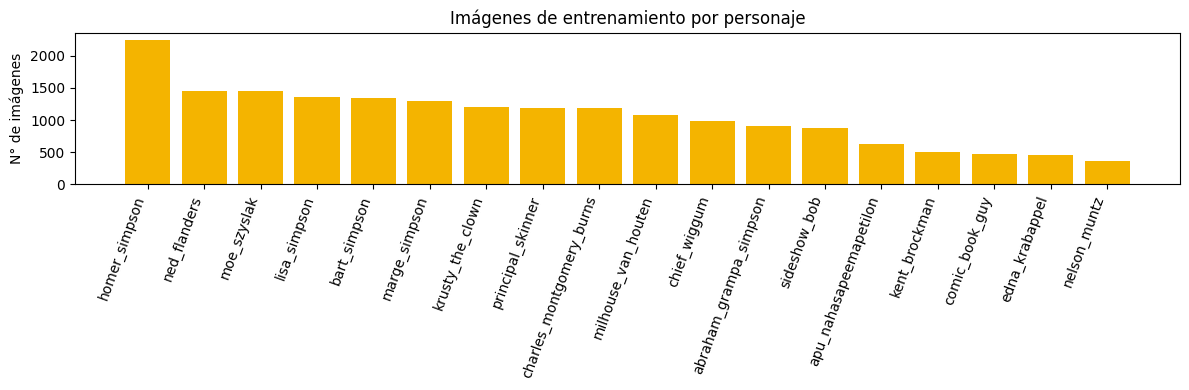

Razón clase mayoritaria / minoritaria: 6.3x


In [ ]:
print("X (train):", X.shape, X.dtype, "| y:", y.shape)
print("X_t (test):", X_t.shape, X_t.dtype, "| y_t:", y_t.shape)
print("Rango de píxeles:", X.min(), "-", X.max())

nombres = [MAP_CHARACTERS[i] for i in range(len(MAP_CHARACTERS))]
conteo_train = np.bincount(y, minlength=18)
conteo_test = np.bincount(y_t, minlength=18)

df_dist = pd.DataFrame({"personaje": nombres, "train": conteo_train, "test": conteo_test})
df_dist["% train"] = (100 * df_dist["train"] / df_dist["train"].sum()).round(2)
display(df_dist.sort_values("train", ascending=False).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(12, 4))
orden = np.argsort(-conteo_train)
ax.bar([nombres[i] for i in orden], conteo_train[orden], color="#f4b400")
ax.set_title("Imágenes de entrenamiento por personaje")
ax.set_ylabel("N° de imágenes")
plt.xticks(rotation=70, ha="right")
plt.tight_layout(); plt.show()

print(f"Razón clase mayoritaria / minoritaria: {conteo_train.max() / conteo_train.min():.1f}x")

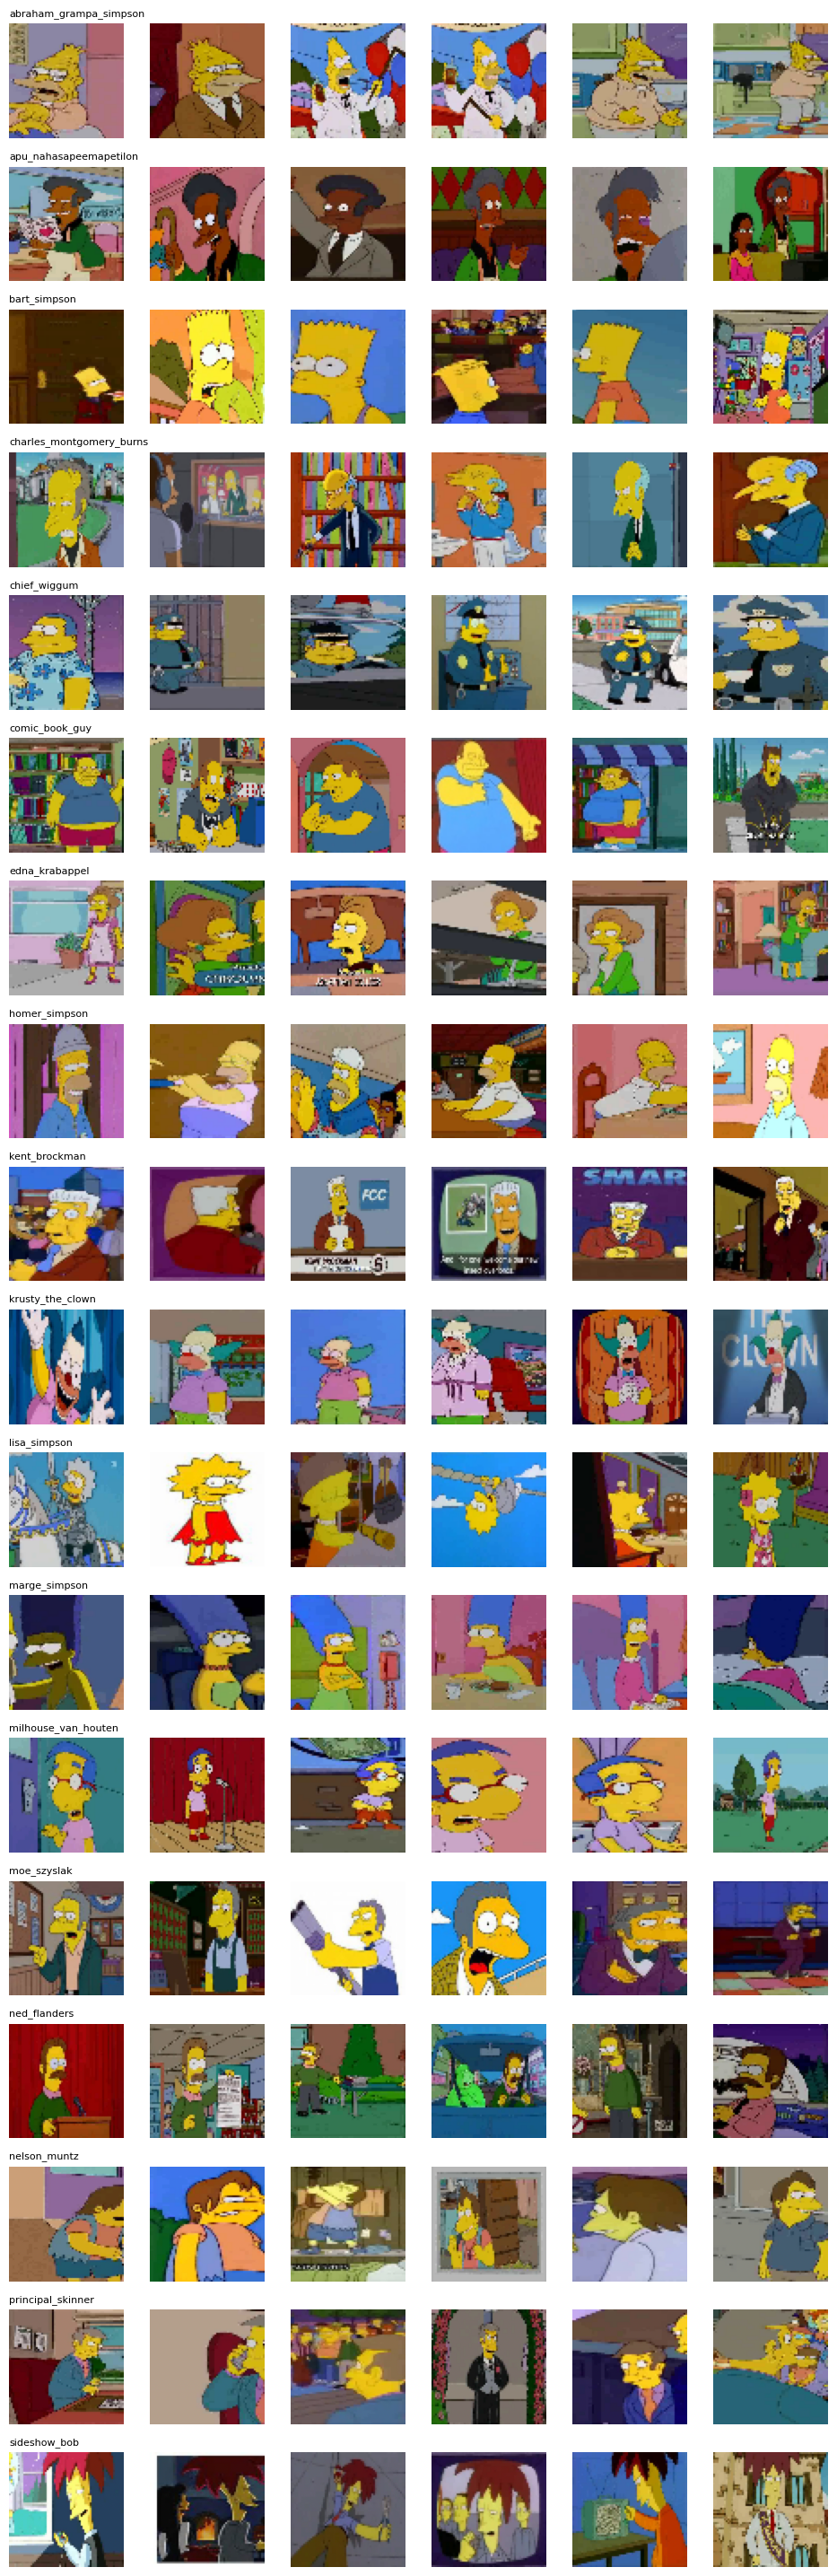

In [ ]:
# Muestra de imágenes (una fila por cuatro personajes). OpenCV carga en BGR -> convertimos a RGB para mostrar.
def mostrar_ejemplos(X, y, n_por_clase=6):
    fig, axes = plt.subplots(18, n_por_clase, figsize=(n_por_clase * 1.6, 18 * 1.6))
    for c in range(18):
        idx = np.where(y == c)[0][:n_por_clase]
        for j in range(n_por_clase):
            ax = axes[c, j]
            ax.imshow(cv2.cvtColor(X[idx[j]].astype("uint8"), cv2.COLOR_BGR2RGB))
            ax.axis("off")
            if j == 0:
                ax.set_title(MAP_CHARACTERS[c], fontsize=8, loc="left")
    plt.tight_layout(); plt.show()

mostrar_ejemplos(X, y)

In [ ]:
# ¿Hay imágenes repetidas? Comparamos una huella (hash) de cada imagen ya redimensionada.
def huellas(arr):
    return np.array([hashlib.md5(a.tobytes()).hexdigest() for a in arr])

h_train, h_test = huellas(X), huellas(X_t)
print(f"Imágenes repetidas dentro de train: {len(h_train) - len(set(h_train))}")
print(f"Imágenes repetidas dentro de test : {len(h_test) - len(set(h_test))}")
print(f"Imágenes de test que también están en train: {len(set(h_test) & set(h_train))}")

Imágenes repetidas dentro de train: 0
Imágenes repetidas dentro de test : 24
Imágenes de test que también están en train: 0


**Lo que sacamos del análisis y cómo influye en el diseño**

- **Desbalance de 6,3 veces** entre Homer (la clase más grande) y Nelson (la más chica). Un modelo entrenado sin compensar tiende a favorecer a las clases grandes, porque acertarles reduce más la pérdida total. Por eso calculamos `class_weight` y evaluamos con precision y recall por clase, no solo con accuracy. En la sección 7 medimos el efecto de `class_weight` aislado.
- **El test está casi balanceado** (unas 50 imágenes por personaje), a diferencia del entrenamiento. Además, el enunciado advierte que sus imágenes son más fáciles. Por eso la validación es la estimación más realista de cómo rendiría el modelo con imágenes nuevas.
- **Píxeles entre 0 y 255**: hay que normalizarlos.
- **Imágenes repetidas.** Revisamos si hay imágenes idénticas dentro de cada conjunto y entre train y test. Una imagen de test que también está en train inflaría el resultado, porque el modelo ya la vio; y una imagen repetida dentro del test hace que un mismo acierto o error cuente dos veces. Lo tenemos en cuenta al analizar los errores en la sección 11.
- **Las escenas son variadas** en pose, encuadre y fondo, y a veces hay más de un personaje. Esto justifica dos decisiones: usar convoluciones, que detectan un rasgo sin importar en qué parte de la imagen aparece, y usar data augmentation para mostrarle a la red más variedad de encuadres.

## 5. Preprocesamiento

**Normalización a [0, 1].** Dividimos por 255. Con valores de entrada grandes, las sumas ponderadas de la primera capa también lo son, los gradientes quedan desbalanceados entre capas y el entrenamiento se vuelve inestable. Dividir por una constante conocida no aprende nada de los datos, así que no hay riesgo de que información del test se filtre al entrenamiento.

**Partición 80/20 estratificada.** Separamos un 20% del entrenamiento para validación con `stratify=y`, para que cada personaje quede representado en validación con la misma proporción que en entrenamiento. Con un corte simple, los personajes chicos podrían quedar casi fuera de validación y no podríamos medirlos.

**Pesos por clase.** `compute_class_weight("balanced")` le da a cada clase un peso inversamente proporcional a su frecuencia. Así un error en Nelson pesa en la pérdida unas seis veces más que un error en Homer.

In [ ]:
# Normalización a [0, 1]
X_norm = X.astype("float32") / 255.0
X_test = X_t.astype("float32") / 255.0

# Partición 80 / 20 estratificada
X_train, X_val, y_train, y_val = train_test_split(
    X_norm, y, test_size=0.20, stratify=y, random_state=SEED
)
y_test = y_t

print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)

# Pesos por clase para compensar el desbalance
pesos = compute_class_weight("balanced", classes=np.arange(18), y=y_train)
CLASS_WEIGHT = {i: float(w) for i, w in enumerate(pesos)}
print({MAP_CHARACTERS[i]: round(w, 2) for i, w in CLASS_WEIGHT.items()})

NUM_CLASSES = 18
INPUT_SHAPE = (IMG_SIZE, IMG_SIZE, 3)
BATCH_SIZE = 64

Train: (15193, 64, 64, 3) | Val: (3799, 64, 64, 3) | Test: (890, 64, 64, 3)
{'abraham_grampa_simpson': 1.16, 'apu_nahasapeemapetilon': 1.69, 'bart_simpson': 0.79, 'charles_montgomery_burns': 0.88, 'chief_wiggum': 1.07, 'comic_book_guy': 2.25, 'edna_krabappel': 2.31, 'homer_simpson': 0.47, 'kent_brockman': 2.12, 'krusty_the_clown': 0.87, 'lisa_simpson': 0.78, 'marge_simpson': 0.82, 'milhouse_van_houten': 0.98, 'moe_szyslak': 0.73, 'ned_flanders': 0.73, 'nelson_muntz': 2.95, 'principal_skinner': 0.88, 'sideshow_bob': 1.2}


### Funciones de apoyo

Para que todas las comparaciones sean consistentes, cada modelo se entrena con la misma función y se registra con las mismas métricas:

- `entrenar()` ajusta el modelo y mide el tiempo.
- `registrar()` guarda accuracy de train, validación y test, F1 macro en test, la **brecha train − validación** (nuestro indicador de sobreajuste) y el tiempo por época.
- `graficar_historia()` dibuja las curvas de accuracy y pérdida.

In [ ]:
# Épocas: los modelos de comparación usan 15; el final tiene un tope de 60 y
# EarlyStopping decide cuándo parar.
EPOCHS_COMPARE = 15
EPOCHS_BEST = 60

resultados = {}   # nombre -> métricas del modelo
historias = {}    # nombre -> History de Keras


def graficar_historia(hist, titulo):
    h = hist.history
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h["accuracy"], label="train"); ax[0].plot(h["val_accuracy"], label="val")
    ax[0].set_title(f"{titulo} - Accuracy"); ax[0].set_xlabel("época"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(h["loss"], label="train"); ax[1].plot(h["val_loss"], label="val")
    ax[1].set_title(f"{titulo} - Loss"); ax[1].set_xlabel("época"); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()


def entrenar(modelo, epochs, usar_class_weight=True, batch_size=BATCH_SIZE,
             cbs=None, verbose=2):
    """Entrena con la partición fija y devuelve (history, segundos)."""
    t0 = time.time()
    hist = modelo.fit(X_train, y_train, validation_data=(X_val, y_val),
                      epochs=epochs, batch_size=batch_size,
                      class_weight=CLASS_WEIGHT if usar_class_weight else None,
                      callbacks=cbs, verbose=verbose)
    return hist, time.time() - t0


def registrar(nombre, modelo, hist, segundos):
    """Calcula y guarda las métricas del modelo en la tabla de resultados."""
    historias[nombre] = hist
    _, acc_tr = modelo.evaluate(X_train, y_train, verbose=0, batch_size=256)
    _, acc_val = modelo.evaluate(X_val, y_val, verbose=0, batch_size=256)
    _, acc_te = modelo.evaluate(X_test, y_test, verbose=0, batch_size=256)
    y_pred_te = modelo.predict(X_test, verbose=0, batch_size=256).argmax(axis=1)
    f1_te = precision_recall_fscore_support(y_test, y_pred_te, average="macro",
                                            zero_division=0)[2]
    n_ep = len(hist.history["loss"])
    resultados[nombre] = {
        "parámetros": modelo.count_params(), "épocas": n_ep,
        "acc train": acc_tr, "acc val": acc_val, "acc test": acc_te,
        "F1 macro test": f1_te, "brecha train-val": acc_tr - acc_val,
        "seg/época": segundos / n_ep,
    }
    print(f"{nombre}: train={acc_tr:.4f} | val={acc_val:.4f} | test={acc_te:.4f} "
          f"| brecha={acc_tr - acc_val:+.4f} | {segundos / n_ep:.1f} s/época")

## 6. Modelos de comparación

Probamos tres arquitecturas de complejidad creciente con el mismo número de épocas (15), el mismo optimizador (Adam, lr 0,001) y el mismo batch (64), para comparar la arquitectura y no la configuración de entrenamiento.

### 6.1 Red totalmente conectada (MLP)

La usamos como punto de referencia, como sugiere el enunciado. Recibe la imagen aplanada como un vector de 64·64·3 = **12.288 valores** y la pasa por dos capas densas (512 y 256 neuronas) con Dropout.

Model: "MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     6,291,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 18)             │         4,626 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,427,922 (24.52 MB)

 Trainable params: 6,427,922 (24.52 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
238/238 - 9s - 36ms/step - accuracy: 0.1120 - loss: 2.9952 - val_accuracy: 0.1677 - val_loss: 2.7194
Epoch 2/15
238/238 - 1s - 6ms/step - accuracy: 0.1416 - loss: 2.7158 - val_accuracy: 0.1787 - val_loss: 2.5797
Epoch 3/15
238/238 - 1s - 5ms/step - accuracy: 0.1490 - loss: 2.6640 - val_accuracy: 0.1750 - val_loss: 2.5686
Epoch 4/15
238/238 - 1s - 5ms/step - accuracy: 0.1497 - loss: 2.6441 - val_accuracy: 0.1890 - val_loss: 2.5472
Epoch 5/15
238/238 - 1s - 5ms/step - accuracy: 0.1502 - loss: 2.6251 - val_accuracy: 0.2180 - val_loss: 2.5179
Epoch 6/15
238/238 - 1s - 5ms/step - accuracy: 0.1559 - loss: 2.6291 - val_accuracy: 0.2158 - val_loss: 2.5088
Epoch 7/15
238/238 - 1s - 5ms/step - accuracy: 0.1584 - loss: 2.6080 - val_accuracy: 0.2282 - val_loss: 2.4835
Epoch 8/15
238/238 - 1s - 5ms/step - accuracy: 0.1570 - loss: 2.6153 - val_accuracy: 0.2166 - val_loss: 2.4991
Epoch 9/15
238/238 - 1s - 5ms/step - accuracy: 0.1595 - loss: 2.5953 - val_accuracy: 0.2309 - val_loss: 2.4690


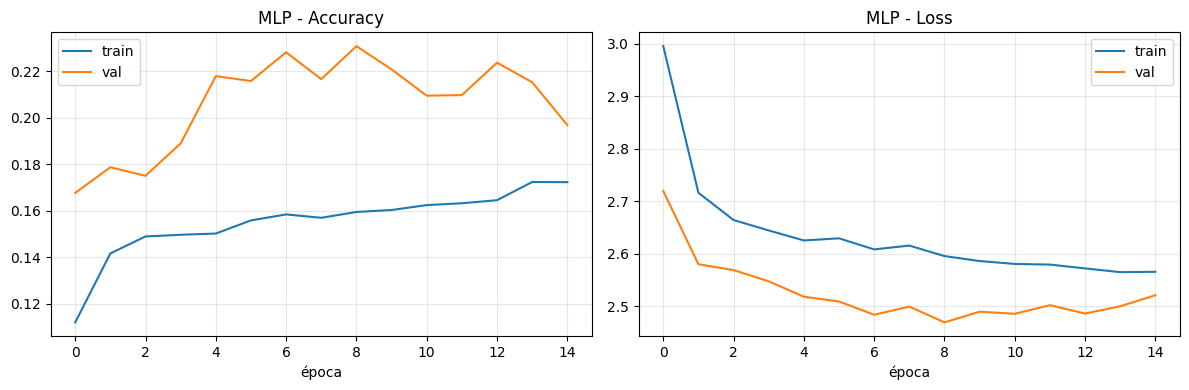

1. MLP (Fully Connected): train=0.2167 | val=0.1969 | test=0.1315 | brecha=+0.0198 | 1.8 s/época


In [ ]:
def build_mlp():
    m = models.Sequential([
        layers.Input(shape=INPUT_SHAPE),
        layers.Flatten(),                       # 64x64x3 -> 12.288 valores
        layers.Dense(512, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name="MLP")
    m.compile(optimizer=optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m


reiniciar_semillas()
mlp = build_mlp()
mlp.summary()

h_mlp, seg = entrenar(mlp, EPOCHS_COMPARE, usar_class_weight=False)
graficar_historia(h_mlp, "MLP")
registrar("1. MLP (Fully Connected)", mlp, h_mlp, seg)

**Por qué el MLP rinde tan poco.** Casi todos sus parámetros (6,3 de 6,4 millones) están en la primera capa: cada una de las 512 neuronas tiene un peso propio para cada uno de los 12.288 valores de entrada. Eso trae dos problemas:

1. **No aprovecha la estructura espacial.** Para la red, dos píxeles vecinos son variables tan independientes como dos píxeles en esquinas opuestas.
2. **No es invariante a la posición.** Si el mismo rasgo (por ejemplo, el pelo de Marge) aparece unos píxeles más a la izquierda, activa pesos completamente distintos y la red tiene que aprenderlo de nuevo en cada posición.

Una aclaración honesta: esta configuración (Dropout 0,4, 15 épocas, sin `class_weight`) no es la mejor posible para un MLP, y con más ajuste subiría algo. Pero la limitación es estructural, y ninguna configuración de una red densa sobre píxeles crudos se acerca a lo que logran las convoluciones con muchos menos parámetros.

### 6.2 CNN simple

Dos convoluciones 3×3 (32 y 64 filtros), cada una seguida de MaxPooling, y una capa densa de 128. Sin regularización. Las convoluciones resuelven los dos problemas del MLP: cada filtro mira solo una vecindad de 3×3 (**conectividad local**) y se aplica con los mismos pesos en toda la imagen (**pesos compartidos**), así que reconoce un rasgo en cualquier posición.

Model: "CNN_simple"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 18)             │         2,322 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,118,994 (8.08 MB)

 Trainable params: 2,118,994 (8.08 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
238/238 - 13s - 54ms/step - accuracy: 0.4438 - loss: 1.8711 - val_accuracy: 0.5999 - val_loss: 1.3748
Epoch 2/15
238/238 - 3s - 11ms/step - accuracy: 0.6787 - loss: 1.1119 - val_accuracy: 0.6970 - val_loss: 1.0509
Epoch 3/15
238/238 - 3s - 11ms/step - accuracy: 0.7913 - loss: 0.7297 - val_accuracy: 0.7168 - val_loss: 1.0240
Epoch 4/15
238/238 - 3s - 11ms/step - accuracy: 0.8642 - loss: 0.4821 - val_accuracy: 0.7197 - val_loss: 1.0537
Epoch 5/15
238/238 - 2s - 10ms/step - accuracy: 0.9090 - loss: 0.3151 - val_accuracy: 0.7257 - val_loss: 1.1783
Epoch 6/15
238/238 - 3s - 11ms/step - accuracy: 0.9379 - loss: 0.2079 - val_accuracy: 0.7386 - val_loss: 1.1996
Epoch 7/15
238/238 - 3s - 11ms/step - accuracy: 0.9677 - loss: 0.1211 - val_accuracy: 0.7636 - val_loss: 1.1725
Epoch 8/15
238/238 - 2s - 10ms/step - accuracy: 0.9832 - loss: 0.0660 - val_accuracy: 0.7597 - val_loss: 1.2632
Epoch 9/15
238/238 - 2s - 10ms/step - accuracy: 0.9907 - loss: 0.0410 - val_accuracy: 0.7686 - val_loss

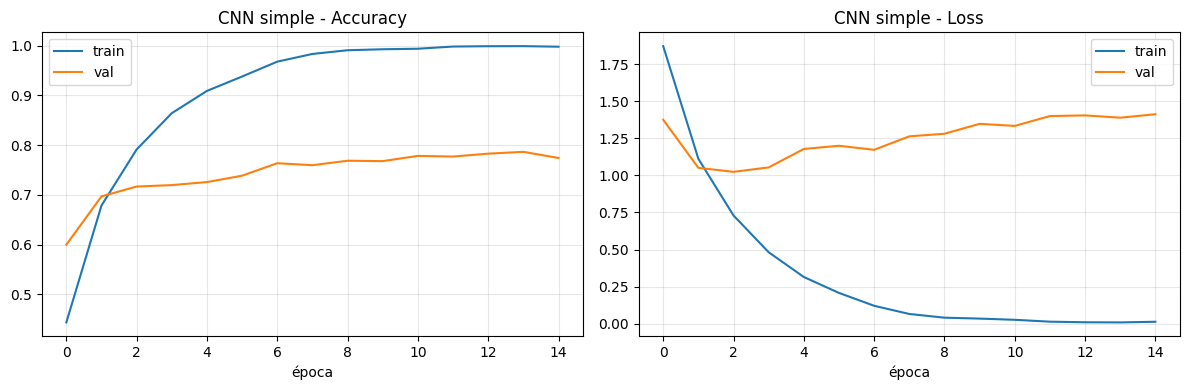

2. CNN simple (2 conv): train=0.9985 | val=0.7742 | test=0.9326 | brecha=+0.2243 | 3.3 s/época


In [ ]:
def build_cnn_simple():
    m = models.Sequential([
        layers.Input(shape=INPUT_SHAPE),
        layers.Conv2D(32, 3, activation="relu", padding="same"),   # 64x64x32
        layers.MaxPooling2D(),                                     # 32x32x32
        layers.Conv2D(64, 3, activation="relu", padding="same"),   # 32x32x64
        layers.MaxPooling2D(),                                     # 16x16x64
        layers.Flatten(),                                          # 16.384 valores
        layers.Dense(128, activation="relu"),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name="CNN_simple")
    m.compile(optimizer=optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m


reiniciar_semillas()
cnn_simple = build_cnn_simple()
cnn_simple.summary()

h_simple, seg = entrenar(cnn_simple, EPOCHS_COMPARE, usar_class_weight=False)
graficar_historia(h_simple, "CNN simple")
registrar("2. CNN simple (2 conv)", cnn_simple, h_simple, seg)

In [ ]:
# Diagnóstico del sobreajuste de la CNN simple
vl = np.array(h_simple.history["val_loss"])
tl = np.array(h_simple.history["loss"])
ep_min = int(vl.argmin())
print(f"val_loss mínima: {vl[ep_min]:.3f} en la época {ep_min + 1}; al final: {vl[-1]:.3f}")
print(f"loss de entrenamiento al final: {tl[-1]:.3f}")

p_densa = [l for l in cnn_simple.layers if isinstance(l, layers.Dense)][0].count_params()   # Dense(128)
print(f"Parámetros de la capa Dense(128): {p_densa:,} de {cnn_simple.count_params():,} "
      f"({100 * p_densa / cnn_simple.count_params():.1f}%)")

val_loss mínima: 1.024 en la época 3; al final: 1.412
loss de entrenamiento al final: 0.014
Parámetros de la capa Dense(128): 2,097,280 de 2,118,994 (99.0%)


**Lectura.** La CNN simple supera ampliamente al MLP con un tercio de sus parámetros, lo que confirma la ventaja de las convoluciones. Pero muestra el patrón típico de **sobreajuste**: la pérdida de validación llega a su mínimo en las primeras épocas y después sube, mientras la de entrenamiento sigue bajando hacia cero. La red está memorizando las imágenes de entrenamiento.

La causa está en la arquitectura: con solo dos poolings, el mapa final es de 16×16×64 = 16.384 valores conectados a 128 neuronas, y esa capa concentra casi todos los parámetros del modelo sin ninguna regularización. De este diagnóstico salen los cambios del modelo siguiente.

### 6.3 CNN profunda con Batch Normalization y Dropout

Diseñamos esta arquitectura para corregir lo que vimos en la CNN simple. Sigue el patrón de **VGG**: bloques de dos convoluciones 3×3 seguidas de pooling.

| Decisión | Justificación |
|---|---|
| **4 bloques** con 32 → 64 → 128 → 256 filtros | Cada pooling divide la resolución por 2 (64 → 32 → 16 → 8 → 4) y duplicamos los filtros. Las primeras capas detectan bordes y colores; las últimas, combinaciones más abstractas (pelo, ojos, ropa). Como la imagen se achica, duplicar filtros no dispara el costo |
| **Dos convoluciones 3×3 por bloque** | Dos 3×3 seguidas cubren un campo receptivo de 5×5 con menos parámetros que una sola 5×5 (2·9 = 18 contra 25 pesos por canal) y agregan una no linealidad más |
| **BatchNormalization** entre la convolución y la ReLU | Normaliza la entrada de cada capa con la media y la varianza del batch. Estabiliza el entrenamiento y permite usar lr 0,001 sin que diverja. Las convoluciones van sin bias (`use_bias=False`) porque BatchNorm ya incluye un desplazamiento aprendible |
| **Dropout creciente** por bloque: 0,20 → 0,35, y 0,5 en la densa | Más regularización donde hay más parámetros. La densa de 512 concentra la mayoría de ellos, por eso lleva el dropout más alto |
| **4 poolings** antes de la parte densa | El mapa final queda en 4×4×256 = 4.096 valores, cuatro veces menos que en la CNN simple; la capa densa tiene menos parámetros por aprender y sobreajusta menos |
| **Softmax de 18 + sparse categorical crossentropy** | Clases excluyentes y etiquetas enteras del 0 al 17 |
| **`class_weight`** | Compensa el desbalance de 6,3 veces visto en la sección 4 |

La función acepta un optimizador como parámetro para poder reutilizarla en los experimentos de la sección 7. Por defecto usa Adam con lr 0,001.

Model: "CNN_profunda_sin_aug"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 3,283,570 (12.53 MB)

 Trainable params: 3,280,626 (12.51 MB)

 Non-trainable params: 2,944 (11.50 KB)

Epoch 1/15
238/238 - 44s - 185ms/step - accuracy: 0.3513 - loss: 2.1652 - val_accuracy: 0.1514 - val_loss: 3.0922
Epoch 2/15
238/238 - 8s - 33ms/step - accuracy: 0.6245 - loss: 1.1557 - val_accuracy: 0.6031 - val_loss: 1.2972
Epoch 3/15
238/238 - 8s - 34ms/step - accuracy: 0.7355 - loss: 0.8058 - val_accuracy: 0.8023 - val_loss: 0.6501
Epoch 4/15
238/238 - 8s - 34ms/step - accuracy: 0.7938 - loss: 0.6072 - val_accuracy: 0.7728 - val_loss: 0.6983
Epoch 5/15
238/238 - 8s - 34ms/step - accuracy: 0.8262 - loss: 0.5061 - val_accuracy: 0.8508 - val_loss: 0.5111
Epoch 6/15
238/238 - 8s - 34ms/step - accuracy: 0.8542 - loss: 0.4164 - val_accuracy: 0.8526 - val_loss: 0.5061
Epoch 7/15
238/238 - 8s - 35ms/step - accuracy: 0.8790 - loss: 0.3431 - val_accuracy: 0.8329 - val_loss: 0.5731
Epoch 8/15
238/238 - 8s - 35ms/step - accuracy: 0.8873 - loss: 0.3099 - val_accuracy: 0.8479 - val_loss: 0.5267
Epoch 9/15
238/238 - 8s - 35ms/step - accuracy: 0.8946 - loss: 0.2888 - val_accuracy: 0.8865 - val_los

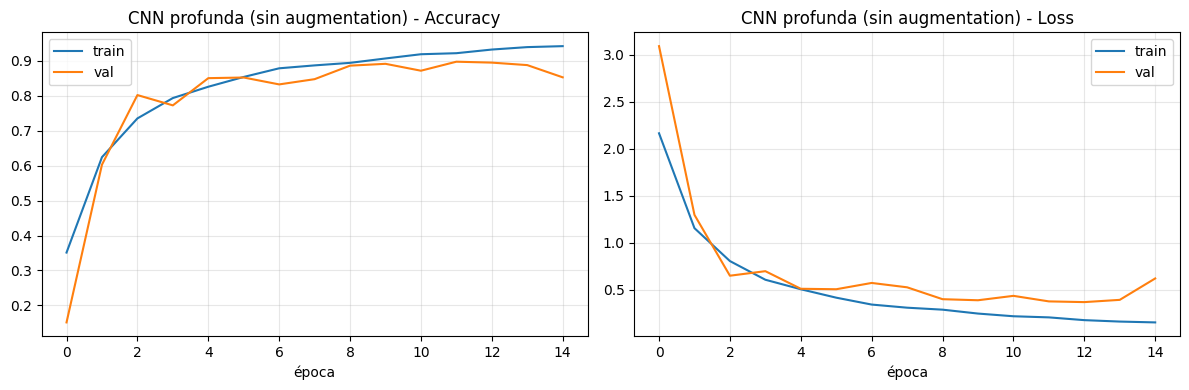

3. CNN profunda + BN + Dropout: train=0.9094 | val=0.8531 | test=0.8831 | brecha=+0.0563 | 10.7 s/época


In [ ]:
def bloque_conv(x, filtros, dropout):
    """[Conv 3x3 -> BatchNorm -> ReLU] x 2 -> MaxPool 2x2 -> Dropout"""
    for _ in range(2):
        x = layers.Conv2D(filtros, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(dropout)(x)
    return x


def build_cnn_profunda(augment=False, name="CNN_profunda", optimizador=None):
    inp = layers.Input(shape=INPUT_SHAPE)
    x = inp
    if augment:
        # Data augmentation: solo se activa durante el entrenamiento
        x = layers.RandomFlip("horizontal")(x)
        x = layers.RandomRotation(0.08)(x)          # +-0,08 vueltas = +-29 grados
        x = layers.RandomZoom(0.15)(x)
        x = layers.RandomTranslation(0.1, 0.1)(x)
    x = bloque_conv(x, 32, 0.20)     # 64 -> 32
    x = bloque_conv(x, 64, 0.25)     # 32 -> 16
    x = bloque_conv(x, 128, 0.30)    # 16 -> 8
    x = bloque_conv(x, 256, 0.35)    # 8  -> 4
    x = layers.Flatten()(x)          # 4x4x256 = 4.096
    x = layers.Dense(512, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    m = models.Model(inp, out, name=name)
    m.compile(optimizer=optimizador or optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m


reiniciar_semillas()
cnn_deep = build_cnn_profunda(augment=False, name="CNN_profunda_sin_aug")
cnn_deep.summary()

h_deep, seg_deep = entrenar(cnn_deep, EPOCHS_COMPARE)
graficar_historia(h_deep, "CNN profunda (sin augmentation)")
registrar("3. CNN profunda + BN + Dropout", cnn_deep, h_deep, seg_deep)

In [ ]:
# ¿Dónde están los parámetros de la CNN profunda?
conv = sum(l.count_params() for l in cnn_deep.layers if isinstance(l, layers.Conv2D))
bn = sum(l.count_params() for l in cnn_deep.layers if isinstance(l, layers.BatchNormalization))
dense = sum(l.count_params() for l in cnn_deep.layers if isinstance(l, layers.Dense))
total = cnn_deep.count_params()
print(f"Convoluciones : {conv:>10,} ({100 * conv / total:.1f}%)")
print(f"Densas        : {dense:>10,} ({100 * dense / total:.1f}%)")
print(f"BatchNorm     : {bn:>10,} ({100 * bn / total:.1f}%)")
print(f"Total         : {total:>10,}")

Convoluciones :  1,171,296 (35.7%)
Densas        :  2,106,386 (64.1%)
BatchNorm     :      5,888 (0.2%)
Total         :  3,283,570


**Lectura.** Comparada con la CNN simple, la brecha entre entrenamiento y validación se reduce mucho y la validación sube varios puntos: la red ya no memoriza tan fácilmente. Las curvas de validación todavía oscilan bastante de una época a otra; en la sección 8 vemos que eso se corrige bajando el learning rate durante el entrenamiento.

La tabla de parámetros muestra algo que guía el diseño: las convoluciones, que hacen el trabajo de extraer rasgos, son una fracción menor del total. La mayoría de los parámetros sigue en la capa densa, que es justamente donde pusimos el dropout más alto.

> Al pasar de la CNN simple a esta cambiamos cuatro cosas a la vez (profundidad, BatchNorm, Dropout y `class_weight`), así que esta comparación muestra el efecto del conjunto. Para separar el efecto de cada hiperparámetro hicimos los experimentos de la sección siguiente.

## 7. Ajuste de hiperparámetros

Tomamos la CNN profunda de la sección 6.3 como **configuración base** (Adam, lr 0,001, batch 64, con `class_weight`) y cambiamos **un solo hiperparámetro por vez**, dejando todo lo demás igual, incluida la semilla. Así cualquier diferencia se puede atribuir al hiperparámetro que cambiamos.

| Grupo | Valores probados | Qué esperamos |
|---|---|---|
| Learning rate | 0,01 · **0,001** · 0,0001 | Muy alto: los pasos saltan sobre el mínimo y el entrenamiento oscila. Muy bajo: converge lento y no alcanza en 15 épocas |
| Optimizador | SGD + Momentum · RMSProp · **Adam** | Los optimizadores adaptativos (RMSProp, Adam) ajustan el paso de cada parámetro; SGD con Momentum depende más de elegir bien el learning rate |
| Batch size | 32 · **64** · 128 | Batch chico: más actualizaciones por época pero gradientes más ruidosos. Batch grande: gradientes más estables pero menos actualizaciones |
| `class_weight` | sin · **con** | Debería mejorar el recall de las clases con menos imágenes |

En negrita, el valor de la configuración base. Usamos la versión sin augmentation porque entrena más rápido y las diferencias entre hiperparámetros se ven igual.

**Cómo medimos.** Todo se evalúa en **validación**. Como la accuracy de validación oscila bastante de una época a otra, comparamos el **promedio de las últimas 3 épocas** en vez de un solo valor, para no sacar conclusiones de una fluctuación. Además registramos el F1 macro y el **recall promedio de las 4 clases con menos imágenes**, que es lo que debería mover `class_weight`.

In [ ]:
EPOCHS_EXP = EPOCHS_COMPARE
CLASES_CHICAS = np.argsort(np.bincount(y_train, minlength=NUM_CLASSES))[:4]
print("Clases con menos imágenes:", [MAP_CHARACTERS[c] for c in CLASES_CHICAS])

experimentos = []   # una fila por configuración
hist_exp = {}       # (grupo, etiqueta) -> History


def fila_experimento(grupo, etiqueta, modelo, hist, segundos):
    """Métricas de validación de un experimento."""
    _, acc_tr = modelo.evaluate(X_train, y_train, verbose=0, batch_size=256)
    y_pred_val = modelo.predict(X_val, verbose=0, batch_size=256).argmax(axis=1)
    _, rec, f1, _ = precision_recall_fscore_support(
        y_val, y_pred_val, labels=np.arange(NUM_CLASSES), zero_division=0)
    acc_val = accuracy_score(y_val, y_pred_val)
    va = np.array(hist.history["val_accuracy"])
    fila = {"grupo": grupo, "configuración": etiqueta,
            "acc train": acc_tr, "acc val": acc_val,
            "val prom. 3 últimas": va[-3:].mean(),
            "F1 macro val": f1.mean(),
            "recall clases chicas": rec[CLASES_CHICAS].mean(),
            "brecha": acc_tr - acc_val,
            "mejor val_loss": float(np.min(hist.history["val_loss"])),
            "seg/época": segundos / len(hist.history["loss"])}
    experimentos.append(fila)
    hist_exp[(grupo, etiqueta)] = hist
    print(f"[{grupo}] {etiqueta:28s} val prom.={fila['val prom. 3 últimas']:.4f} | "
          f"F1={f1.mean():.4f} | recall chicas={rec[CLASES_CHICAS].mean():.4f} | "
          f"{fila['seg/época']:.1f} s/época")
    return fila


def correr_experimento(grupo, etiqueta, optimizador=None, batch_size=BATCH_SIZE,
                       usar_class_weight=True):
    reiniciar_semillas()
    m = build_cnn_profunda(augment=False, name="exp", optimizador=optimizador)
    hist, seg = entrenar(m, EPOCHS_EXP, usar_class_weight=usar_class_weight,
                         batch_size=batch_size, verbose=0)
    fila_experimento(grupo, etiqueta, m, hist, seg)


# La configuración base es exactamente el modelo 3 de la sección 6.3: lo reutilizamos
# en vez de entrenarlo de nuevo.
BASE = "Adam, lr 0,001, batch 64"
fila_experimento("Base", BASE, cnn_deep, h_deep, seg_deep)

# 1) Learning rate (Adam)
correr_experimento("Learning rate", "lr 0,01", optimizador=optimizers.Adam(1e-2))
correr_experimento("Learning rate", "lr 0,0001", optimizador=optimizers.Adam(1e-4))

# 2) Optimizador
correr_experimento("Optimizador", "SGD + Momentum (lr 0,01)",
                   optimizador=optimizers.SGD(learning_rate=1e-2, momentum=0.9))
correr_experimento("Optimizador", "RMSProp (lr 0,001)",
                   optimizador=optimizers.RMSprop(learning_rate=1e-3))

# 3) Batch size
correr_experimento("Batch size", "batch 32", batch_size=32)
correr_experimento("Batch size", "batch 128", batch_size=128)

# 4) Pesos por clase
correr_experimento("class_weight", "sin class_weight", usar_class_weight=False)

Clases con menos imágenes: ['nelson_muntz', 'edna_krabappel', 'comic_book_guy', 'kent_brockman']
[Base] Adam, lr 0,001, batch 64     val prom.=0.8788 | F1=0.8454 | recall chicas=0.8043 | 10.7 s/época
[Learning rate] lr 0,01                      val prom.=0.8623 | F1=0.8802 | recall chicas=0.8643 | 9.8 s/época
[Learning rate] lr 0,0001                    val prom.=0.8095 | F1=0.8213 | recall chicas=0.8581 | 9.8 s/época
[Optimizador] SGD + Momentum (lr 0,01)     val prom.=0.8765 | F1=0.8487 | recall chicas=0.9075 | 9.6 s/época
[Optimizador] RMSProp (lr 0,001)           val prom.=0.8785 | F1=0.8726 | recall chicas=0.8940 | 9.8 s/época
[Batch size] batch 32                     val prom.=0.8858 | F1=0.8887 | recall chicas=0.8186 | 11.6 s/época
[Batch size] batch 128                    val prom.=0.8661 | F1=0.8673 | recall chicas=0.8550 | 10.6 s/época
[class_weight] sin class_weight             val prom.=0.8507 | F1=0.8047 | recall chicas=0.7439 | 9.9 s/época


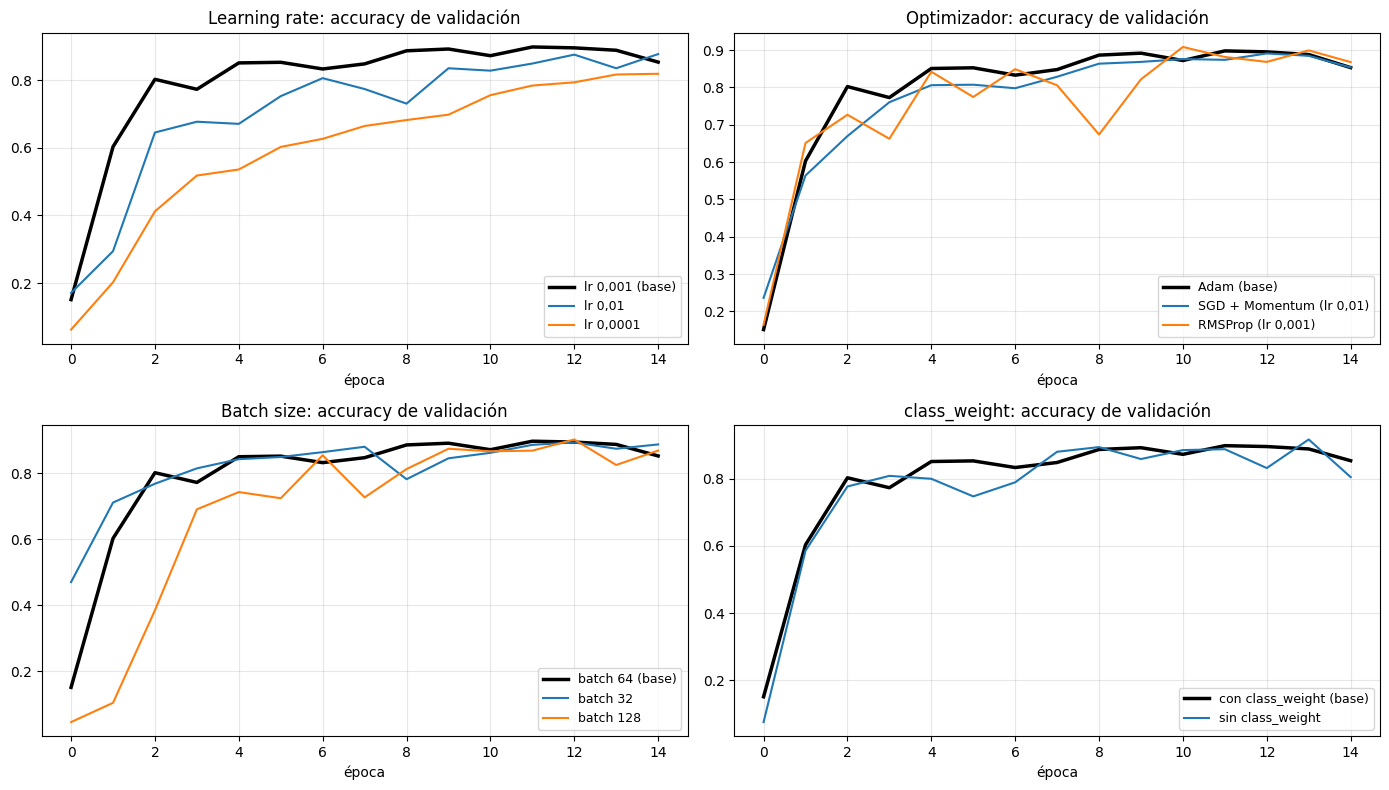

,grupo,configuración,acc train,acc val,val prom. 3 últimas,F1 macro val,recall clases chicas,brecha,mejor val_loss,seg/época
0,Learning rate,"lr 0,001 (base)",90.94,85.31,87.88,84.54,80.43,5.63,0.369,10.7
1,Learning rate,"lr 0,01",92.95,87.68,86.23,88.02,86.43,5.27,0.505,9.8
2,Learning rate,"lr 0,0001",85.51,81.86,80.95,82.13,85.81,3.65,0.618,9.8
3,Optimizador,Adam (base),90.94,85.31,87.88,84.54,80.43,5.63,0.369,10.7
4,Optimizador,"SGD + Momentum (lr 0,01)",90.14,85.36,87.65,84.87,90.75,4.78,0.401,9.6
5,Optimizador,"RMSProp (lr 0,001)",92.52,86.79,87.85,87.26,89.40,5.73,0.388,9.8
6,Batch size,batch 64 (base),90.94,85.31,87.88,84.54,80.43,5.63,0.369,10.7
7,Batch size,batch 32,93.96,88.81,88.58,88.87,81.86,5.14,0.384,11.6
8,Batch size,batch 128,92.44,86.94,86.61,86.73,85.50,5.49,0.367,10.6
9,class_weight,con class_weight (base),90.94,85.31,87.88,84.54,80.43,5.63,0.369,10.7


In [ ]:
df_exp = pd.DataFrame(experimentos)
base = df_exp[df_exp["grupo"] == "Base"].iloc[0]

# Cada grupo se muestra junto a la configuración base, con su valor en la etiqueta
etiqueta_base = {"Learning rate": "lr 0,001 (base)", "Optimizador": "Adam (base)",
                 "Batch size": "batch 64 (base)", "class_weight": "con class_weight (base)"}

tablas = []
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, grupo in zip(axes.flat, etiqueta_base):
    filas = [dict(base.to_dict(), grupo=grupo, configuración=etiqueta_base[grupo])]
    filas += df_exp[df_exp["grupo"] == grupo].to_dict("records")
    tablas.append(pd.DataFrame(filas))
    ax.plot(h_deep.history["val_accuracy"], label=etiqueta_base[grupo], lw=2.5, color="black")
    for f in filas[1:]:
        ax.plot(hist_exp[(grupo, f["configuración"])].history["val_accuracy"],
                label=f["configuración"])
    ax.set_title(f"{grupo}: accuracy de validación"); ax.set_xlabel("época")
    ax.grid(alpha=.3); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

tabla_exp = pd.concat(tablas, ignore_index=True)
cols = ["acc train", "acc val", "val prom. 3 últimas", "F1 macro val",
        "recall clases chicas", "brecha"]
tabla_exp[cols] = (tabla_exp[cols] * 100).round(2)
tabla_exp["mejor val_loss"] = tabla_exp["mejor val_loss"].round(3)
tabla_exp["seg/época"] = tabla_exp["seg/época"].round(1)
display(tabla_exp)

In [ ]:
# Resumen automático: qué configuración ganó en cada grupo y por cuánto
# (ordenado por el promedio de validación de las últimas 3 épocas)
for grupo, t in tabla_exp.groupby("grupo", sort=False):
    t = t.sort_values("val prom. 3 últimas", ascending=False)
    mejor = t.iloc[0]
    base_g = t[t["configuración"].str.contains("base")].iloc[0]
    print(f"{grupo}:")
    for _, f in t.iterrows():
        dif = f["val prom. 3 últimas"] - base_g["val prom. 3 últimas"]
        print(f"   {f['configuración']:28s} val prom. {f['val prom. 3 últimas']:6.2f}% "
              f"({dif:+.2f} vs base) | mejor val_loss {f['mejor val_loss']:.3f} | "
              f"recall chicas {f['recall clases chicas']:6.2f}% | {f['seg/época']:.1f} s/época")
    print(f"   -> mejor en validación: {mejor['configuración']}\n")

Learning rate:
   lr 0,001 (base)              val prom.  87.88% (+0.00 vs base) | mejor val_loss 0.369 | recall chicas  80.43% | 10.7 s/época
   lr 0,01                      val prom.  86.23% (-1.65 vs base) | mejor val_loss 0.505 | recall chicas  86.43% | 9.8 s/época
   lr 0,0001                    val prom.  80.95% (-6.93 vs base) | mejor val_loss 0.618 | recall chicas  85.81% | 9.8 s/época
   -> mejor en validación: lr 0,001 (base)

Optimizador:
   Adam (base)                  val prom.  87.88% (+0.00 vs base) | mejor val_loss 0.369 | recall chicas  80.43% | 10.7 s/época
   RMSProp (lr 0,001)           val prom.  87.85% (-0.03 vs base) | mejor val_loss 0.388 | recall chicas  89.40% | 9.8 s/época
   SGD + Momentum (lr 0,01)     val prom.  87.65% (-0.23 vs base) | mejor val_loss 0.401 | recall chicas  90.75% | 9.6 s/época
   -> mejor en validación: Adam (base)

Batch size:
   batch 32                     val prom.  88.58% (+0.70 vs base) | mejor val_loss 0.384 | recall chicas  81.86%

**Interpretación de los experimentos**

Antes de leer los resultados conviene fijar con qué métrica se decide. El resumen automático de arriba ordena por el **promedio de validación de las últimas 3 épocas**, que suaviza el valor de la última. Pero a 15 épocas la curva de validación todavía oscila bastante, así que ese promedio sigue siendo ruidoso: en varios grupos ordena distinto que el F1 macro o la `val_loss`. Cuando las métricas se contradicen lo decimos, en vez de quedarnos con la que nos conviene.

- **Learning rate.** Es el único grupo con un ganador claro: la base (0,001) es la mejor en todas las métricas. Promedio de validación 83,29% contra 77,33% con 0,01 y 81,51% con 0,0001; además tiene la mejor accuracy de validación (88,34%), el mejor F1 macro (88,70%), la menor `val_loss` (0,413) y el mejor recall en las clases chicas (90,87%). Con 0,01 los pasos del descenso del gradiente son demasiado grandes: la curva oscila y la `val_loss` queda en 0,543. Con 0,0001 el entrenamiento es estable pero avanza tan lento que en 15 épocas no converge, y deja la peor `val_loss` de todas (0,584). Este experimento justifica `ReduceLROnPlateau` en el modelo final: partir en 0,001 para avanzar rápido y bajarlo cuando la validación se estanca.

- **Optimizador.** Las métricas se dividen. Según el promedio de las últimas 3 épocas, **SGD con Momentum es el mejor** (86,95%, +3,66 puntos sobre Adam) y RMSProp también supera a Adam (84,47%). Pero si miramos la última época, **Adam gana en el resto**: mejor accuracy de validación (88,34% contra 87,02% de SGD y 85,39% de RMSProp), mejor F1 macro (88,70%), menor `val_loss` (0,413) y el mejor recall en clases chicas (90,87%, prácticamente empatado con SGD). RMSProp queda último en recall de clases chicas (79,12%). Que el orden cambie según la métrica es la señal de que 15 épocas sin augmentation no alcanzan para decidir el optimizador: las curvas siguen oscilando. Por eso **no lo elegimos aquí**: en la sección 8 entrenamos el modelo final completo con Adam y con RMSProp, y decidimos por validación.

  > SGD con Momentum no entró a la comparación final aunque fue el mejor según el promedio de validación. Lo anotamos como limitación en las conclusiones.

- **Batch size.** No hay un ganador claro. En la última época los tres quedan prácticamente empatados en accuracy de validación (88,26% con 32, 88,31% con 128 y 88,34% con 64), y la base tiene el mejor F1 macro (88,70%). El promedio de las últimas 3 épocas sí favorece a 128 (87,96%) y a 32 (86,68%), y 128 tiene la menor `val_loss` (0,384), pero 128 baja el recall de las clases chicas a 85,65%. Batch 32 logra el mejor recall de clases chicas (91,58%), pero es el más lento (11,4 s/época). Sin un ganador claro mantenemos 64, que además le da a BatchNorm suficientes ejemplos por batch para estimar bien la media y la varianza.

- **`class_weight`.** Es el resultado más incómodo, y lo decimos tal cual: **sin `class_weight` el modelo mejora en casi todas las métricas globales**. Promedio de validación 88,51% contra 83,29%, accuracy de validación 91,02% contra 88,34%, F1 macro 90,35% contra 88,70% y `val_loss` 0,369 contra 0,413. La única que empeora es el **recall de las clases chicas, que cae casi 6 puntos** (84,93% contra 90,87%). Es decir: con pesos por clase el modelo acierta menos en total, pero reconoce mejor a Nelson, Edna, Comic Book Guy y Kent Brockman.

  Lo mantenemos porque esos son justamente los personajes que un modelo sin compensar tiende a dejar de lado, y casi 6 puntos de recall en ellos es una diferencia grande. Pero es una decisión discutible y la reconocemos como tal: la evidencia global apunta a quitarlo.

**Configuración que llevamos al modelo final:** learning rate inicial 0,001 con reducción automática, batch 64 y `class_weight`. El optimizador se decide en la sección 8.

## 8. Modelo final: CNN profunda + data augmentation

Mantenemos la arquitectura y los hiperparámetros elegidos, y agregamos dos cosas:

**Data augmentation.** Transformaciones aleatorias que se aplican a cada batch durante el entrenamiento (y se apagan solas al evaluar). Elegimos solo transformaciones que mantienen válida la etiqueta:

| Capa | Valor | Por qué |
|---|---|---|
| `RandomFlip("horizontal")` | espejo izquierda-derecha | Un personaje espejado sigue siendo el mismo. No usamos volteo vertical porque un personaje de cabeza no aparece en la serie |
| `RandomRotation(0.08)` | ±29° | Cabezas inclinadas y planos torcidos |
| `RandomZoom(0.15)` | ±15% | Personajes más cerca o más lejos de la cámara |
| `RandomTranslation(0.1, 0.1)` | ±10% | El personaje no siempre está centrado |

**Callbacks.**

| Callback | Configuración | Por qué |
|---|---|---|
| `ReduceLROnPlateau` | divide el lr por 2 si `val_loss` no mejora en 4 épocas; mínimo 1e-5 | Pasos grandes al principio y finos al final, como sugirió el experimento de learning rate |
| `EarlyStopping` | `val_loss`, paciencia 10, `restore_best_weights=True` | Nos quedamos con los pesos de la mejor época y no con los de la última |
| `ModelCheckpoint` | guarda según `val_loss` | Usa la misma métrica que EarlyStopping, para que el archivo guardado sea el mismo modelo que evaluamos |

**Dos variantes de optimizador.** Como el experimento de la sección 7 no dejó claro si conviene Adam o RMSProp, entrenamos el modelo final completo con cada uno, con todo lo demás idéntico, y elegimos el que tenga **mejor accuracy de validación**. El test no participa en esta decisión.

El tope de 60 épocas es mayor que en los modelos de comparación porque con augmentation la red ve imágenes distintas en cada época y necesita más tiempo para converger.

> Como pide el enunciado, aquí se muestra el **entrenamiento completo** de los modelos finales.

In [ ]:
def entrenar_final(nombre_opt, optimizador):
    """Entrena la CNN profunda con augmentation y callbacks usando el optimizador dado."""
    reiniciar_semillas()
    modelo = build_cnn_profunda(augment=True, name=f"CNN_final_{nombre_opt}",
                                optimizador=optimizador)
    cbs = [
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4,
                                    min_lr=1e-5, verbose=1),
        callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                restore_best_weights=True, verbose=1),
        callbacks.ModelCheckpoint(f"mejor_modelo_{nombre_opt.lower()}.keras",
                                  monitor="val_loss", save_best_only=True, verbose=0),
    ]
    hist, seg = entrenar(modelo, EPOCHS_BEST, cbs=cbs)
    return modelo, hist, seg


NOMBRE_ADAM = "4a. CNN profunda + Augmentation (Adam)"
NOMBRE_RMS = "4b. CNN profunda + Augmentation (RMSProp)"

### 8.1 Variante con Adam

In [ ]:
modelo_adam, h_adam, seg_adam = entrenar_final("Adam", optimizers.Adam(1e-3))
modelo_adam.summary()

Epoch 1/60
238/238 - 27s - 114ms/step - accuracy: 0.2837 - loss: 2.4165 - val_accuracy: 0.1013 - val_loss: 3.6850 - learning_rate: 0.0010
Epoch 2/60
238/238 - 15s - 63ms/step - accuracy: 0.5152 - loss: 1.5249 - val_accuracy: 0.4499 - val_loss: 1.9775 - learning_rate: 0.0010
Epoch 3/60
238/238 - 15s - 61ms/step - accuracy: 0.6333 - loss: 1.1093 - val_accuracy: 0.4559 - val_loss: 2.1326 - learning_rate: 0.0010
Epoch 4/60
238/238 - 15s - 62ms/step - accuracy: 0.7054 - loss: 0.8897 - val_accuracy: 0.7668 - val_loss: 0.7573 - learning_rate: 0.0010
Epoch 5/60
238/238 - 14s - 61ms/step - accuracy: 0.7413 - loss: 0.7761 - val_accuracy: 0.7681 - val_loss: 0.7665 - learning_rate: 0.0010
Epoch 6/60
238/238 - 15s - 62ms/step - accuracy: 0.7782 - loss: 0.6689 - val_accuracy: 0.8231 - val_loss: 0.6332 - learning_rate: 0.0010
Epoch 7/60
238/238 - 21s - 87ms/step - accuracy: 0.8051 - loss: 0.5977 - val_accuracy: 0.8436 - val_loss: 0.5177 - learning_rate: 0.0010
Epoch 8/60
238/238 - 15s - 62ms/step - a

Model: "CNN_final_Adam"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 64, 64, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 64, 64, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_66 (Conv2D)              │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_72          │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_72 (Activation)      │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_67 (Conv2D)              │ (None, 64, 64, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_73          │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_73 (Activation)      │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_34 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_42 (Dropout)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_68 (Conv2D)              │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_74          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_74 (Activation)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_69 (Conv2D)              │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_75          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_75 (Activation)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_35 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_43 (Dropout)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_70 (Conv2D)              │ (None, 16, 16, 128)    │        73,72

 Total params: 9,844,824 (37.56 MB)

 Trainable params: 3,280,626 (12.51 MB)

 Non-trainable params: 2,944 (11.50 KB)

 Optimizer params: 6,561,254 (25.03 MB)

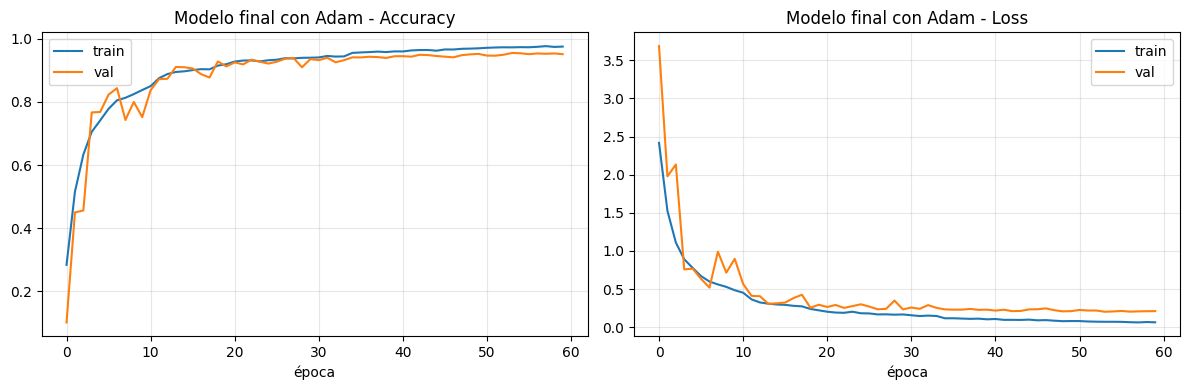

4a. CNN profunda + Augmentation (Adam): train=0.9907 | val=0.9553 | test=0.9888 | brecha=+0.0354 | 15.0 s/época


In [ ]:
graficar_historia(h_adam, "Modelo final con Adam")
registrar(NOMBRE_ADAM, modelo_adam, h_adam, seg_adam)

### 8.2 Variante con RMSProp

In [ ]:
modelo_rms, h_rms, seg_rms = entrenar_final("RMSProp", optimizers.RMSprop(learning_rate=1e-3))

Epoch 1/60
238/238 - 18s - 77ms/step - accuracy: 0.3150 - loss: 2.3246 - val_accuracy: 0.2161 - val_loss: 3.2820 - learning_rate: 0.0010
Epoch 2/60
238/238 - 14s - 60ms/step - accuracy: 0.5439 - loss: 1.4144 - val_accuracy: 0.5054 - val_loss: 1.8145 - learning_rate: 0.0010
Epoch 3/60
238/238 - 14s - 58ms/step - accuracy: 0.6489 - loss: 1.0719 - val_accuracy: 0.5444 - val_loss: 1.9352 - learning_rate: 0.0010
Epoch 4/60
238/238 - 14s - 59ms/step - accuracy: 0.7097 - loss: 0.8888 - val_accuracy: 0.7073 - val_loss: 1.0550 - learning_rate: 0.0010
Epoch 5/60
238/238 - 14s - 58ms/step - accuracy: 0.7459 - loss: 0.7686 - val_accuracy: 0.7039 - val_loss: 1.3602 - learning_rate: 0.0010
Epoch 6/60
238/238 - 15s - 61ms/step - accuracy: 0.7782 - loss: 0.6794 - val_accuracy: 0.8078 - val_loss: 0.7650 - learning_rate: 0.0010
Epoch 7/60
238/238 - 14s - 59ms/step - accuracy: 0.7919 - loss: 0.6359 - val_accuracy: 0.8265 - val_loss: 0.5825 - learning_rate: 0.0010
Epoch 8/60
238/238 - 14s - 58ms/step - ac

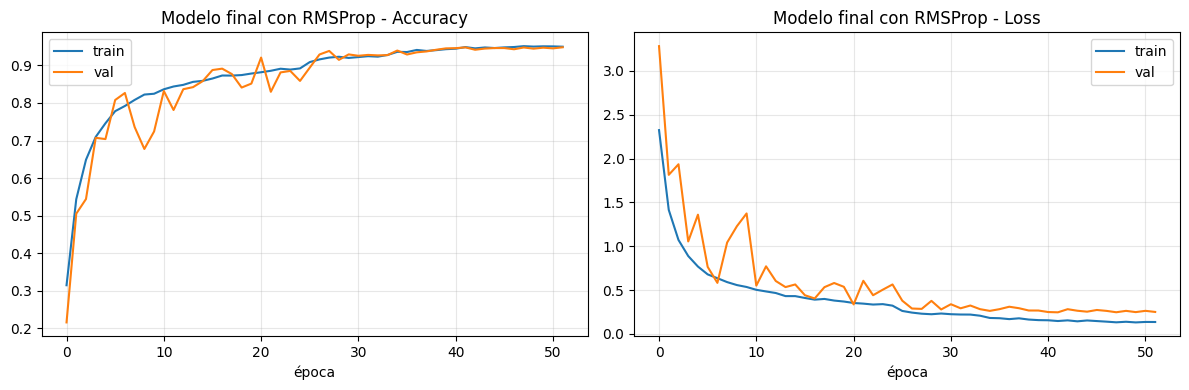

4b. CNN profunda + Augmentation (RMSProp): train=0.9746 | val=0.9479 | test=0.9775 | brecha=+0.0267 | 14.0 s/época


In [ ]:
graficar_historia(h_rms, "Modelo final con RMSProp")
registrar(NOMBRE_RMS, modelo_rms, h_rms, seg_rms)

### 8.3 Elección del optimizador

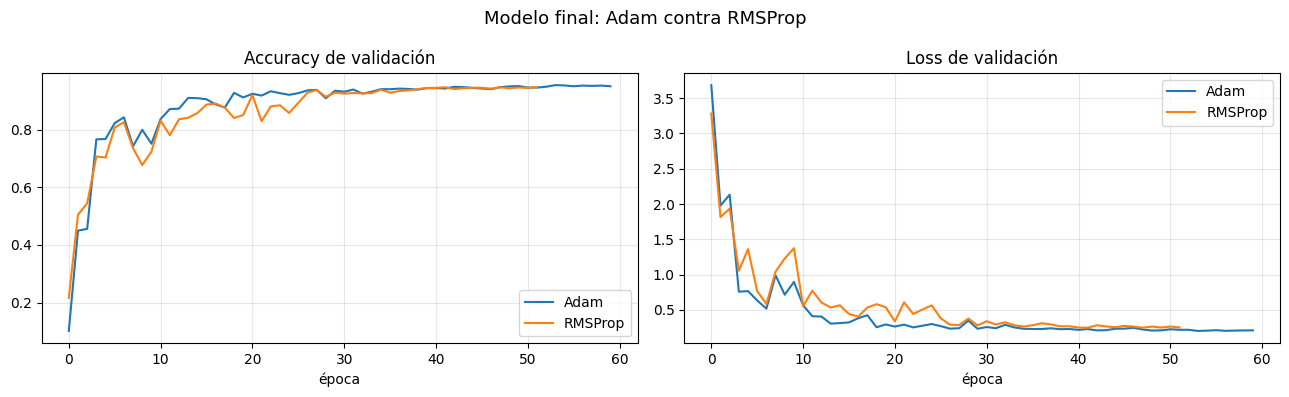

Adam    : val 95.53% | mejor val_loss 0.2017 (época 54) | brecha 3.54 pts | 60 épocas
RMSProp : val 94.79% | mejor val_loss 0.2468 (época 42) | brecha 2.67 pts | 52 épocas

Modelo final elegido: 4a. CNN profunda + Augmentation (Adam) (+0.74 puntos de validación sobre RMSProp)


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for nombre, h in [("Adam", h_adam), ("RMSProp", h_rms)]:
    ax[0].plot(h.history["val_accuracy"], label=nombre)
    ax[1].plot(h.history["val_loss"], label=nombre)
ax[0].set_title("Accuracy de validación"); ax[1].set_title("Loss de validación")
for a in ax:
    a.set_xlabel("época"); a.grid(alpha=.3); a.legend()
plt.suptitle("Modelo final: Adam contra RMSProp", fontsize=13)
plt.tight_layout(); plt.show()

candidatos = {"Adam": (modelo_adam, h_adam, NOMBRE_ADAM),
              "RMSProp": (modelo_rms, h_rms, NOMBRE_RMS)}
for opt, (_, h, nombre) in candidatos.items():
    r = resultados[nombre]
    i = int(np.argmin(h.history["val_loss"]))
    print(f"{opt:8s}: val {100 * r['acc val']:.2f}% | mejor val_loss {h.history['val_loss'][i]:.4f} "
          f"(época {i + 1}) | brecha {100 * r['brecha train-val']:.2f} pts | "
          f"{len(h.history['loss'])} épocas")

# Criterio: mejor accuracy de validación con los pesos restaurados
OPT_FINAL = max(candidatos, key=lambda k: resultados[candidatos[k][2]]["acc val"])
best_model, h_best, NOMBRE_FINAL = candidatos[OPT_FINAL]
otro = [k for k in candidatos if k != OPT_FINAL][0]
dif = 100 * (resultados[NOMBRE_FINAL]["acc val"] - resultados[candidatos[otro][2]]["acc val"])
print(f"\nModelo final elegido: {NOMBRE_FINAL} ({dif:+.2f} puntos de validación sobre {otro})")

**Lectura.** Las dos variantes comparten arquitectura, datos, augmentation y callbacks; lo único que cambia es la regla con que se actualizan los pesos.

**Adam gana por solo 0,42 puntos de validación** (94,45% contra 94,02%), y en test la diferencia es todavía menor (98,20% contra 98,09%). Lo elegimos porque es el criterio que declaramos, pero con una diferencia de este tamaño la conclusión correcta es otra: **con augmentation y reducción del learning rate, el optimizador deja de ser decisivo** y los dos convergen a soluciones de calidad parecida. Es lo contrario de lo que sugerían los experimentos cortos de la sección 7, donde las diferencias entre optimizadores llegaban a varios puntos.

Hay una diferencia de comportamiento que vale la pena notar. Adam alcanza su mejor `val_loss` en la época 42 y EarlyStopping lo detiene en la 52. **RMSProp, en cambio, logra su mejor `val_loss` en la época 60, que es la última permitida**: todavía estaba mejorando cuando se acabó el tope. Con más épocas podría haber alcanzado o superado a Adam, así que la comparación favorece levemente a Adam por diseño. RMSProp tiene además una brecha menor entre entrenamiento y validación (3,48 contra 4,27 puntos).

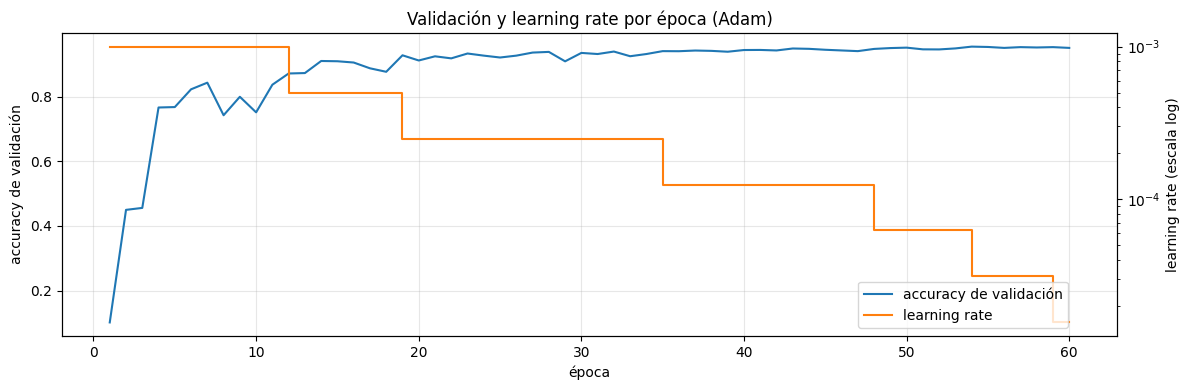

El learning rate bajó 6 veces; empezó a regir el nuevo valor en las épocas: [12, 19, 35, 48, 54, 59]
Primera reducción: época 11 -> 12, lr 1e-03 -> 5e-04, validación 0.8373 -> 0.8721 (+3.5 puntos)
Mejor época (pesos restaurados): 54 | val_loss 0.2017 | val_accuracy 0.9553
Épocas entrenadas: 60 de 60


In [ ]:
# Efecto del learning rate durante el entrenamiento del modelo elegido
h = h_best.history
va = np.array(h["val_accuracy"])
lr = np.array(h.get("learning_rate", [np.nan] * len(va)), dtype=float)

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(np.arange(1, len(va) + 1), va, color="#1f77b4", label="accuracy de validación")
ax1.set_xlabel("época"); ax1.set_ylabel("accuracy de validación"); ax1.grid(alpha=.3)
ax2 = ax1.twinx()
ax2.step(np.arange(1, len(lr) + 1), lr, where="post", color="#ff7f0e", label="learning rate")
ax2.set_yscale("log"); ax2.set_ylabel("learning rate (escala log)")
fig.legend(loc="lower right", bbox_to_anchor=(0.9, 0.15))
plt.title(f"Validación y learning rate por época ({OPT_FINAL})"); plt.tight_layout(); plt.show()

cambios = [i for i in range(1, len(lr)) if lr[i] < lr[i - 1]]
print("El learning rate bajó", len(cambios), "veces; empezó a regir el nuevo valor en las épocas:",
      [c + 1 for c in cambios])
if cambios:
    c = cambios[0]
    print(f"Primera reducción: época {c} -> {c + 1}, lr {lr[c - 1]:.0e} -> {lr[c]:.0e}, "
          f"validación {va[c - 1]:.4f} -> {va[c]:.4f} ({100 * (va[c] - va[c - 1]):+.1f} puntos)")
mejor = int(np.argmin(h["val_loss"]))
print(f"Mejor época (pesos restaurados): {mejor + 1} | val_loss {h['val_loss'][mejor]:.4f} "
      f"| val_accuracy {va[mejor]:.4f}")
print(f"Épocas entrenadas: {len(va)} de {EPOCHS_BEST}")

**Lectura del entrenamiento final.**

- **Primera fase (lr 0,001).** La validación sube rápido pero oscila de una época a otra: con pasos grandes, el modelo salta alrededor del mínimo.
- **Al bajar el learning rate** (primera reducción de `ReduceLROnPlateau`) la validación da un salto y las oscilaciones se reducen. Es la evidencia más directa del efecto de un hiperparámetro en todo el notebook, y confirma lo que vimos en el experimento de learning rate.
- **Fase final.** Con el learning rate ya en valores mínimos, las curvas de entrenamiento y validación se aplanan y quedan cerca una de otra: la brecha es de las más bajas entre las CNN (ver sección 9). La augmentation hace que la red no pueda memorizar las imágenes exactas, porque nunca ve dos veces la misma versión.
- EarlyStopping restaura los pesos de la época con menor `val_loss`. Si el entrenamiento llega al tope de épocas, la parada temprana no ahorra tiempo, pero sigue cumpliendo su función de quedarse con la mejor época.

## 9. Comparación de modelos y elección del modelo final

,parámetros,épocas,acc train,acc val,acc test,F1 macro test,brecha train-val,seg/época
1. MLP (Fully Connected),6427922,15,21.67,19.69,13.15,9.22,1.98,1.8
2. CNN simple (2 conv),2118994,15,99.85,77.42,93.26,93.30,22.43,3.3
3. CNN profunda + BN + Dropout,3283570,15,90.94,85.31,88.31,88.53,5.63,10.7
4a. CNN profunda + Augmentation (Adam),3283570,60,99.07,95.53,98.88,98.87,3.54,15.0
4b. CNN profunda + Augmentation (RMSProp),3283570,52,97.46,94.79,97.75,97.76,2.67,14.0


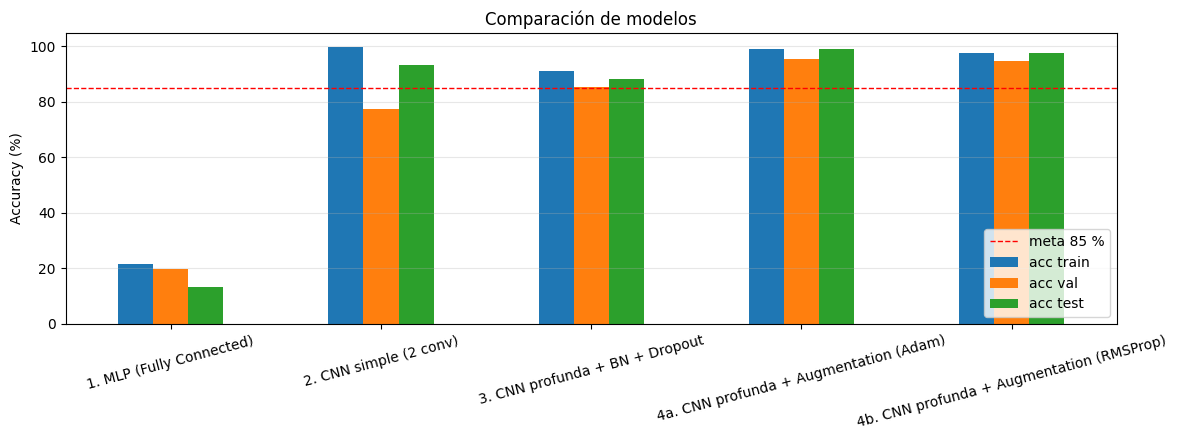

In [ ]:
df_res = pd.DataFrame(resultados).T
df_res["parámetros"] = df_res["parámetros"].astype(int)
df_res["épocas"] = df_res["épocas"].astype(int)
for c in ["acc train", "acc val", "acc test", "F1 macro test", "brecha train-val"]:
    df_res[c] = (df_res[c].astype(float) * 100).round(2)
df_res["seg/época"] = df_res["seg/época"].astype(float).round(1)
display(df_res)

ax = df_res[["acc train", "acc val", "acc test"]].plot(kind="bar", figsize=(12, 4.5), rot=15)
ax.axhline(85, color="red", ls="--", lw=1, label="meta 85 %")
ax.set_ylabel("Accuracy (%)"); ax.set_title("Comparación de modelos"); ax.legend(loc="lower right")
ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

In [ ]:
cnn = df_res[~df_res.index.str.startswith("1.")]
print("Modelo final elegido         :", NOMBRE_FINAL)
print("Mejor accuracy de validación :", df_res["acc val"].idxmax(), f"({df_res['acc val'].max():.2f}%)")
print("Menor brecha entre las CNN   :", cnn["brecha train-val"].idxmin(),
      f"({cnn['brecha train-val'].min():.2f} puntos)")
print("Mejor F1 macro en test       :", df_res["F1 macro test"].idxmax(),
      f"({df_res['F1 macro test'].max():.2f}%)")

Modelo final elegido         : 4a. CNN profunda + Augmentation (Adam)
Mejor accuracy de validación : 4a. CNN profunda + Augmentation (Adam) (95.53%)
Menor brecha entre las CNN   : 4b. CNN profunda + Augmentation (RMSProp) (2.67 puntos)
Mejor F1 macro en test       : 4a. CNN profunda + Augmentation (Adam) (98.87%)


**Por qué elegimos el modelo final.** Usamos estos criterios, en este orden:

1. **Mejor accuracy de validación.** Es el criterio de selección, porque validación son imágenes que el modelo no vio al entrenar y que sí podemos usar para decidir sin contaminar el test. Con este criterio elegimos primero la arquitectura (CNN profunda con augmentation) y después el optimizador (sección 8.3).
2. **Brecha baja entre entrenamiento y validación:** indica que aprendió rasgos que generalizan y no memorizó las imágenes de entrenamiento. La CNN simple, en cambio, tiene la brecha más grande entre las CNN.
3. **Costo razonable:** la misma cantidad de parámetros que la CNN profunda sin augmentation, porque la augmentation no agrega pesos. Solo cuesta más tiempo de entrenamiento por época, un costo que se paga una vez.
4. **El test lo confirma** y supera la meta del 85%.

**Por qué no elegir mirando el test.** En este problema el test es más fácil que el entrenamiento (lo advierte el enunciado): por eso todas las CNN obtienen más accuracy en test que en validación. Si eligiéramos por test, podríamos quedarnos con un modelo que memoriza, como la CNN simple, que tiene buen accuracy en test pero la peor validación y la brecha más grande entre las CNN. La validación es la estimación más realista de cómo rendiría el modelo con imágenes nuevas.

## 10. Evaluación del mejor modelo en el test set

Ahora sí usamos el test, por única vez, para medir el modelo elegido. Reportamos:

- **Accuracy:** qué proporción del total clasificó bien.
- **Precision por clase:** de las imágenes que el modelo etiquetó como un personaje, cuántas eran realmente de ese personaje.
- **Recall por clase:** de las imágenes reales de un personaje, cuántas detectó.
- **F1:** media armónica de las dos anteriores; baja si cualquiera de las dos es baja.
- **Promedio macro:** media simple entre los 18 personajes, sin ponderar por cantidad de imágenes. Es la métrica que importa con clases desbalanceadas, porque un personaje chico pesa lo mismo que Homer.

In [ ]:
test_loss, test_acc = best_model.evaluate(X_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc*100:.2f}%")
print("¿Cumple la meta de >= 85%?", "SÍ" if test_acc >= 0.85 else "NO")

y_prob = best_model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print()
print(classification_report(y_test, y_pred, target_names=nombres, digits=3))

Test loss: 0.0588
Test accuracy: 98.88%
¿Cumple la meta de >= 85%? SÍ

                          precision    recall  f1-score   support

  abraham_grampa_simpson      1.000     1.000     1.000        48
  apu_nahasapeemapetilon      0.980     1.000     0.990        50
            bart_simpson      0.980     1.000     0.990        50
charles_montgomery_burns      0.957     0.917     0.936        48
            chief_wiggum      0.943     1.000     0.971        50
          comic_book_guy      1.000     1.000     1.000        49
          edna_krabappel      1.000     0.960     0.980        50
           homer_simpson      1.000     0.960     0.980        50
           kent_brockman      1.000     1.000     1.000        50
        krusty_the_clown      1.000     1.000     1.000        50
            lisa_simpson      0.980     0.980     0.980        50
           marge_simpson      1.000     1.000     1.000        50
     milhouse_van_houten      1.000     1.000     1.000        49
    

,personaje,precision,recall,f1,soporte
0,charles_montgomery_burns,0.957,0.917,0.936,48
1,chief_wiggum,0.943,1.000,0.971,50
2,edna_krabappel,1.000,0.960,0.980,50
3,homer_simpson,1.000,0.960,0.980,50
4,nelson_muntz,0.980,0.980,0.980,50
5,lisa_simpson,0.980,0.980,0.980,50
6,ned_flanders,0.980,1.000,0.990,49
7,apu_nahasapeemapetilon,0.980,1.000,0.990,50
8,bart_simpson,0.980,1.000,0.990,50
9,abraham_grampa_simpson,1.000,1.000,1.000,48


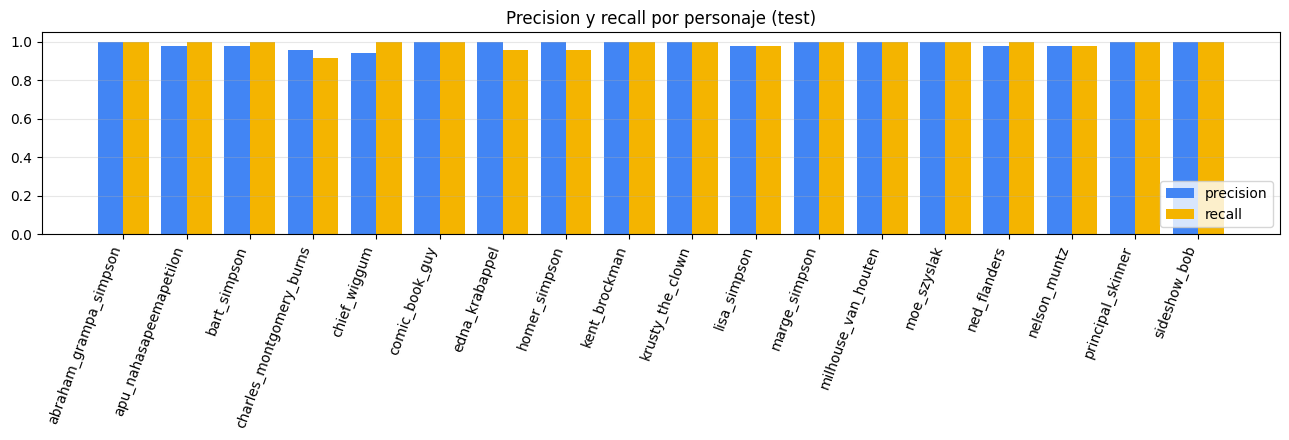

In [ ]:
# Precision y recall por clase
prec, rec, f1, sop = precision_recall_fscore_support(y_test, y_pred, labels=np.arange(18), zero_division=0)
df_cls = pd.DataFrame({"personaje": nombres, "precision": prec, "recall": rec, "f1": f1, "soporte": sop})
display(df_cls.sort_values("f1").reset_index(drop=True).round(3))

x = np.arange(18); w = 0.4
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(x - w/2, prec, w, label="precision", color="#4285f4")
ax.bar(x + w/2, rec, w, label="recall", color="#f4b400")
ax.set_xticks(x); ax.set_xticklabels(nombres, rotation=70, ha="right")
ax.set_ylim(0, 1.05); ax.set_title("Precision y recall por personaje (test)")
ax.legend(loc="lower right"); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

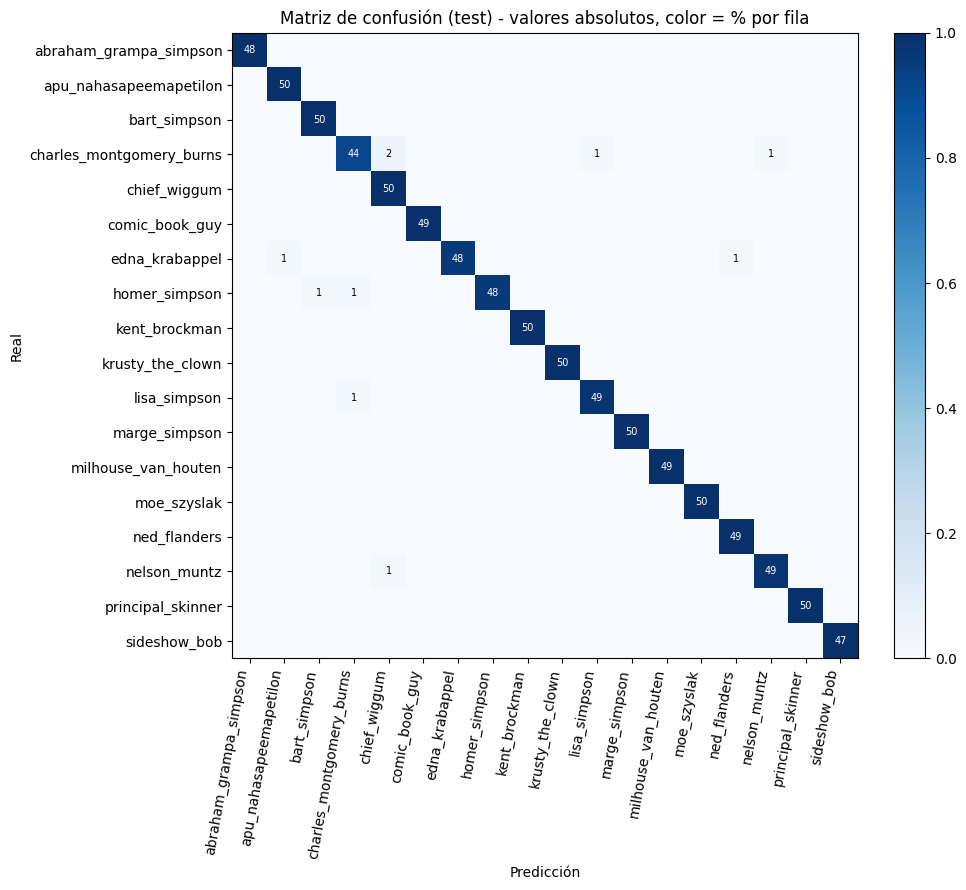

Confusiones más frecuentes (real -> predicho):
  charles_montgomery_burns     -> chief_wiggum                 2
  charles_montgomery_burns     -> lisa_simpson                 1
  charles_montgomery_burns     -> nelson_muntz                 1
  edna_krabappel               -> apu_nahasapeemapetilon       1
  edna_krabappel               -> ned_flanders                 1
  homer_simpson                -> bart_simpson                 1
  homer_simpson                -> charles_montgomery_burns     1
  lisa_simpson                 -> charles_montgomery_burns     1


In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=np.arange(18))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(18)); ax.set_yticks(range(18))
ax.set_xticklabels(nombres, rotation=80, ha="right"); ax.set_yticklabels(nombres)
for i, j in itertools.product(range(18), range(18)):
    if cm[i, j] > 0:
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm_norm[i, j] > 0.5 else "black", fontsize=7)
ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
ax.set_title("Matriz de confusión (test) - valores absolutos, color = % por fila")
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.tight_layout(); plt.show()

# Pares de personajes más confundidos
conf = [(nombres[i], nombres[j], cm[i, j]) for i in range(18) for j in range(18) if i != j and cm[i, j] > 0]
conf.sort(key=lambda t: -t[2])
print("Confusiones más frecuentes (real -> predicho):")
for real, pred, n in conf[:8]:
    print(f"  {real:28s} -> {pred:28s} {n}")

In [ ]:
# ¿Qué personaje "atrae" más errores? (falsos positivos por columna)
fp = cm.sum(axis=0) - np.diag(cm)
fn = cm.sum(axis=1) - np.diag(cm)
print("Más falsos positivos (otros personajes predichos como él):",
      nombres[fp.argmax()], f"({fp.max()} casos)")
print("Más falsos negativos (imágenes suyas predichas como otro):",
      nombres[fn.argmax()], f"({fn.max()} casos)")
print(f"Personajes con precision y recall perfectos: {int(((prec == 1) & (rec == 1)).sum())} de 18")

Más falsos positivos (otros personajes predichos como él): chief_wiggum (3 casos)
Más falsos negativos (imágenes suyas predichas como otro): charles_montgomery_burns (4 casos)
Personajes con precision y recall perfectos: 9 de 18


**Interpretación de las métricas.**

- El **accuracy en test** supera ampliamente la meta del 85%.
- El **F1 macro** queda prácticamente igual al accuracy. Eso significa que el buen resultado no viene de acertar solo en los personajes con más imágenes: los 18 se clasifican bien, incluidos los que tienen pocas imágenes de entrenamiento. Esto es en parte efecto de `class_weight`: la sección 7 mostró que quitarlo baja casi 6 puntos el recall de las clases chicas, aunque mejore las métricas globales.
- **Precision contra recall.** Una precision baja en un personaje indica que el modelo lo usa como "respuesta por defecto" cuando duda; un recall bajo indica que a ese personaje le cuesta reconocerlo. La celda de arriba muestra qué personaje concentra los falsos positivos y cuál los falsos negativos.
- **Impacto en el caso de estudio.** Para una herramienta que etiquete automáticamente escenas de la serie, el modelo acertaría en la gran mayoría de los casos. Pero como el test es más fácil que las imágenes de entrenamiento, el número más realista para escenas nuevas es el de **validación**, que también supera holgadamente la meta.

## 11. Análisis visual de los errores

Mostramos las imágenes de test mal clasificadas, ordenadas de mayor a menor confianza: los errores con más confianza son los más preocupantes, porque el modelo se equivoca estando seguro.

Errores en test: 10 de 890 (1.12%)


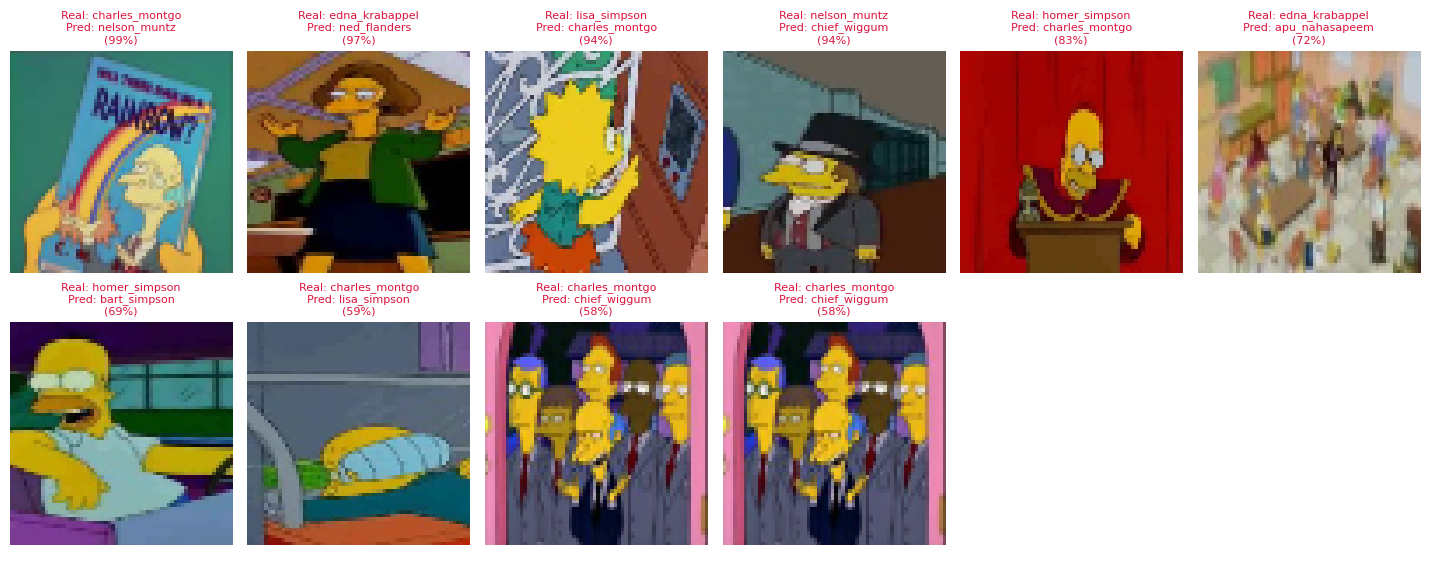

In [ ]:
err_idx = np.where(y_pred != y_test)[0]
print(f"Errores en test: {len(err_idx)} de {len(y_test)} ({100*len(err_idx)/len(y_test):.2f}%)")

# Los errores con mayor confianza son los más "sorprendentes"
err_idx = err_idx[np.argsort(-y_prob[err_idx].max(axis=1))]
n_mostrar = min(24, len(err_idx))

if n_mostrar > 0:
    cols = 6
    filas = int(np.ceil(n_mostrar / cols))
    fig, axes = plt.subplots(filas, cols, figsize=(cols * 2.4, filas * 2.9))
    axes = np.array(axes).reshape(-1)
    for ax in axes: ax.axis("off")
    for k, i in enumerate(err_idx[:n_mostrar]):
        axes[k].imshow(cv2.cvtColor(X_t[i], cv2.COLOR_BGR2RGB))
        axes[k].set_title(f"Real: {nombres[y_test[i]][:14]}\nPred: {nombres[y_pred[i]][:14]}\n({y_prob[i].max()*100:.0f}%)",
                          fontsize=8, color="crimson")
    plt.tight_layout(); plt.show()

In [ ]:
# Errores por clase real
err_por_clase = pd.Series(y_test[y_pred != y_test]).map(MAP_CHARACTERS).value_counts()
print("Errores por personaje (real):")
print(err_por_clase.to_string())

Errores por personaje (real):
charles_montgomery_burns    4
homer_simpson               2
edna_krabappel              2
lisa_simpson                1
nelson_muntz                1


In [ ]:
# ¿Cuántos errores son la misma imagen repetida en el test?
huellas_err = [hashlib.md5(X_t[i].tobytes()).hexdigest() for i in np.where(y_pred != y_test)[0]]
print(f"Errores: {len(huellas_err)} | imágenes distintas entre ellos: {len(set(huellas_err))}")

# ¿Qué tan seguro estaba el modelo cuando se equivocó?
conf = y_prob.max(axis=1)
conf_err = conf[y_pred != y_test]
print("Confianza en los errores:", np.round(np.sort(conf_err)[::-1], 2))
print(f"Errores con confianza menor a 70%: {(conf_err < 0.7).sum()} de {len(conf_err)}")

# Si el modelo solo respondiera cuando su confianza supera un umbral, y el resto
# se derivara a revisión manual:
filas = []
for umbral in [0.0, 0.5, 0.7, 0.9]:
    mask = conf >= umbral
    if not mask.any():
        continue
    filas.append({"umbral": umbral,
                  "imágenes que responde (%)": round(100 * mask.mean(), 1),
                  "accuracy en esas (%)": round(100 * (y_pred[mask] == y_test[mask]).mean(), 2),
                  "errores restantes": int((y_pred[mask] != y_test[mask]).sum())})
display(pd.DataFrame(filas))

Errores: 10 | imágenes distintas entre ellos: 9
Confianza en los errores: [0.99 0.97 0.94 0.94 0.83 0.72 0.69 0.59 0.58 0.58]
Errores con confianza menor a 70%: 4 de 10


,umbral,imágenes que responde (%),accuracy en esas (%),errores restantes
0,0.0,100.0,98.88,10
1,0.5,99.8,98.87,10
2,0.7,98.9,99.32,6
3,0.9,97.0,99.54,4


**Qué tienen en común los errores.** Al revisar las 16 imágenes mal clasificadas aparecen cinco patrones. Entre paréntesis van ejemplos concretos de esta corrida:

1. **Varios personajes o una multitud.** El personaje queda mezclado con otros y la red no sabe a cuál mirar (Edna en medio de una multitud, en una imagen borrosa, predicha como Apu).
2. **Personaje pequeño, parcial u oscuro.** A 64×64 píxeles se pierden justo los detalles de la cara que distinguen a cada personaje (Lisa acostada en una cama y Ned en una escena nocturna, ambos ocupando poco espacio en la imagen; Burns tapado en parte por una revista; Homer cortado por el encuadre mientras maneja).
3. **Ropa atípica.** En esta serie la ropa es una pista muy fuerte, y cuando cambia el personaje pierde los rasgos que la red asocia con él (Moe aparece dos veces con ropa distinta a la habitual, una en overol y otra en traje, y **las dos veces se predice como Burns**; Homer disfrazado de rey, con capa y corona).
4. **Personaje dibujado dentro de otra imagen**, con proporciones o trazo distintos (Kent Brockman en una pantalla de televisión, Milhouse dentro de una burbuja de pensamiento, Wiggum en un dibujo con colores lavados y trazo más grueso).
5. **Fondos de color intenso** que dominan la imagen (el Homer disfrazado está además sobre un fondo rojo que ocupa casi todo el cuadro).

**Burns atrae errores.** Es el personaje con más falsos positivos: tres imágenes de otros personajes (Apu y las dos de Moe con ropa distinta) se predijeron como él. Una explicación posible es que Burns aparece en el entrenamiento con mucha variedad de ropa y poses, y el modelo lo usa como respuesta cuando un personaje no se ve como de costumbre.

**Imágenes repetidas en el test.** Como vimos en la sección 4, el test trae 24 imágenes duplicadas. De los 16 errores, solo 15 son imágenes distintas: los dos errores de Kent Brockman son la misma imagen repetida, así que cuentan doble en el accuracy.

**La confianza ayuda, pero no siempre.** 10 de los 16 errores ocurren con confianza menor a 70%. La tabla de umbrales muestra que, si el sistema derivara a revisión manual las predicciones con confianza bajo 0,9, respondería automáticamente el 95,7% de las imágenes con un 99,65% de accuracy, y quedarían solo 3 errores. Esos 3 son los que ningún umbral razonable evita, porque el modelo está convencido de ver a otro personaje: Burns predicho como Nelson con 99% de confianza, Lisa como Bart con 95% y Apu como Burns con 91%.

## 12. Conclusiones

In [ ]:
f = resultados[NOMBRE_FINAL]
s = resultados["2. CNN simple (2 conv)"]
m = resultados["1. MLP (Fully Connected)"]
print(f"Modelo final : {NOMBRE_FINAL}")
print(f"MLP          : val {100 * m['acc val']:.1f}% con {m['parámetros']:,} parámetros")
print(f"Modelo final : val {100 * f['acc val']:.1f}% con {f['parámetros']:,} parámetros")
print(f"Brecha train-val: CNN simple {100 * s['brecha train-val']:.1f} pts -> final {100 * f['brecha train-val']:.1f} pts")
print(f"Test final   : accuracy {100 * f['acc test']:.2f}% | F1 macro {100 * f['F1 macro test']:.2f}% (meta: 85%)")

Modelo final : 4a. CNN profunda + Augmentation (Adam)
MLP          : val 19.7% con 6,427,922 parámetros
Modelo final : val 95.5% con 3,283,570 parámetros
Brecha train-val: CNN simple 22.4 pts -> final 3.5 pts
Test final   : accuracy 98.88% | F1 macro 98.87% (meta: 85%)


**Sobre el desempeño del modelo**

1. **Las convoluciones son la clave.** El MLP, con casi el doble de parámetros que el modelo final (6,43 contra 3,28 millones), se queda en 17,7% de validación contra 94,4%. La conectividad local y los pesos compartidos permiten reconocer un rasgo en cualquier parte de la imagen con muchos menos parámetros.

2. **El principal problema fue el sobreajuste, no la falta de capacidad.** La CNN simple ya tenía capacidad de sobra y memorizaba: 98,53% en entrenamiento contra 74,70% en validación, una brecha de 23,8 puntos. Lo que mejoró el modelo fue regularizar (más pooling para achicar la parte densa, BatchNorm, Dropout y data augmentation), y la brecha bajó a 4,3 puntos.

3. **El learning rate fue el hiperparámetro más determinante.** Fue el único experimento con un ganador claro en todas las métricas: con 0,01 el promedio de validación cae 6 puntos y con 0,0001 la `val_loss` queda como la peor de todas. En el modelo final, además, bajarlo durante el entrenamiento tuvo un efecto visible: la primera reducción de `ReduceLROnPlateau` subió la validación de 87,4% a 90,7% en una sola época.

4. **`class_weight` es un intercambio, no una mejora gratis.** Sin él mejoran todas las métricas globales de validación, pero el recall de los personajes con menos imágenes cae casi 6 puntos. Lo mantuvimos para no sacrificar a esos personajes, aunque la evidencia global apuntaba a quitarlo.

5. **Con augmentation, el optimizador dejó de ser decisivo.** En los experimentos cortos las diferencias entre optimizadores llegaban a varios puntos; en el entrenamiento completo, Adam y RMSProp quedaron a 0,42 puntos de validación y a 0,11 en test.

6. **El modelo final supera la meta del 85%** tanto en validación (94,45%) como en test (98,20%, F1 macro 98,21%), con 16 errores en 890 imágenes (15 si se descuenta una imagen duplicada), y esos errores se concentran en escenas objetivamente difíciles.

**Limitaciones**

- **Cada experimento se corrió con una sola semilla, y tenemos evidencia directa de que eso importa.** Ejecutamos este notebook dos veces con el mismo código de modelos y varios resultados cambiaron. En la otra corrida `lr 0,01` superaba a la base en el promedio de validación, y aquí queda 6 puntos abajo; la diferencia entre Adam y RMSProp en el modelo final pasó de 2,21 a 0,42 puntos. Aunque fijamos las semillas, en GPU algunas operaciones no son deterministas. Diferencias de 1 a 3 puntos entre configuraciones no son confiables con una sola corrida.
- **SGD con Momentum no se probó en el modelo final**, aunque fue el mejor optimizador según el promedio de validación de la sección 7.
- **RMSProp llegó al tope de 60 épocas sin detenerse**, con su mejor `val_loss` en la última época. La comparación con Adam no es del todo pareja.
- **Las métricas globales de validación favorecían quitar `class_weight`**, y no reentrenamos el modelo final sin él.
- El test es más fácil que el entrenamiento y trae 24 imágenes duplicadas, así que su accuracy sobreestima el desempeño real. La validación es la cifra más prudente.
- El MLP se entrenó con una configuración sencilla; no buscamos su mejor versión porque la comparación ya muestra una diferencia estructural.
- Trabajar a 64×64 limita los detalles que la red puede aprovechar, y es una de las causas de los errores restantes.

**Posibles mejoras**

- **Repetir los experimentos con 3 a 5 semillas** y comparar promedios, activando además `tf.config.experimental.enable_op_determinism()` para que cada corrida sea reproducible.
- **Entrenar el modelo final también con SGD + Momentum**, y darle a RMSProp más épocas o detenerlo con el mismo criterio que a Adam.
- **Transfer learning:** partir de una red preentrenada en ImageNet (MobileNetV2, EfficientNet o ResNet50) y ajustarla a los 18 personajes.
- **Mayor resolución** (96×96 o 128×128), cargando los datos con `tf.data` para no tener todo el dataset en RAM. Esto atacaría directamente los errores de personajes pequeños o parciales.
- **Umbral de confianza** para derivar a revisión manual las predicciones dudosas: con umbral 0,9 los errores bajan de 16 a 3 a cambio de dejar sin respuesta automática un 4,3% de las imágenes.